<div style="background:linear-gradient(135deg,#1E88C8 0%,#6EC6F0 100%);color:#ffffff;padding:34px 40px;border-radius:14px;font-family:Georgia,'Times New Roman',serif;">
  <table style="width:100%;border:none;background:transparent;"><tr style="background:transparent;">
    <td style="border:none;background:transparent;text-align:left;vertical-align:middle;">
      <div style="font-size:13px;letter-spacing:3px;text-transform:uppercase;font-family:Arial,sans-serif;">Python pour la data science · 2ᵉ année</div>
    </td>
  </tr></table>
  <h1 style="color:#ffffff;font-size:40px;margin:22px 0 6px 0;border:none;">Isolement des communes françaises</h1>
  <div style="font-size:20px;margin-bottom:18px;">Deux façons de mesurer l'éloignement aux services du quotidien, et ce qu'elles changent</div>
  <div style="border-top:1px solid rgba(255,255,255,0.6);padding-top:14px;font-size:16px;font-style:italic;">
    À quelle distance de chez soi trouve-t-on les services du quotidien, quelles communes sont les plus éloignées de tout, et la réponse dépend-elle de la façon de mesurer ?
  </div>
</div>

<br>

<div style="border-left:6px solid #1E88C8;background:#EAF6FD;padding:20px 28px;border-radius:0 12px 12px 0;font-family:Arial,sans-serif;color:#12324a;">
  <div style="font-size:13px;letter-spacing:2.5px;text-transform:uppercase;color:#1E88C8;margin-bottom:6px;">Équipe</div>
  <div style="font-size:15px;margin-bottom:14px;">Projet réalisé dans le cadre du cours de Python de 2ᵉ année à l'ENSAE Paris.</div>
  <table style="width:100%;border:none;background:transparent;"><tr style="background:transparent;">
    <td style="border:none;background:transparent;text-align:center;padding:6px;">
      <div style="font-size:17px;font-weight:bold;">FOGWOUNG DJOUFACK</div><div style="font-size:15px;">Sarah-Laure</div>
      <a href="https://github.com/Sarahlaure" style="color:#1E88C8;font-size:13px;">github.com/Sarahlaure</a>
    </td>
    <td style="border:none;background:transparent;text-align:center;padding:6px;">
      <div style="font-size:17px;font-weight:bold;">NGUEMFOUO NGOUMTSA</div><div style="font-size:15px;">Célina</div>
      <a href="https://github.com/nncelina" style="color:#1E88C8;font-size:13px;">github.com/nncelina</a>
    </td>
    <td style="border:none;background:transparent;text-align:center;padding:6px;">
      <div style="font-size:17px;font-weight:bold;">ZAGHROUN</div><div style="font-size:15px;">Eytan</div>
      <a href="https://github.com/Eytan-ZG" style="color:#1E88C8;font-size:13px;">github.com/Eytan-ZG</a>
    </td>
  </tr></table>
</div>

<div style="text-align:center;font-family:Arial,sans-serif;font-size:13px;color:#5f7a8c;margin-top:14px;">
  Données : INSEE (BPE 2025, populations de référence 2023, Filosofi 2023) · IGN (Admin Express COG 2025)
</div>

## Sommaire

- **Introduction** : le sujet, ce qu'on appelle « isolement », la question et les hypothèses
- **Partie 1. Les données** : téléchargement depuis le notebook, panier de services, table des communes
- **Partie 2. Méthode A** : centre géométrique de la commune, tous les services pèsent autant
- **Partie 3. Méthode B** : chef-lieu (mairie) de la commune, distance réelle même quand le service est dans la commune, services pondérés selon leur importance
- **Partie 4. Méthode C** : les 19 services regroupés en 6 grands besoins, qui pèsent chacun autant
- **Partie 5. Analyse des résultats A, B et C** : cartes, densité, revenu
- **Partie 6. Comparaison des méthodes** : qu'est-ce qui change, pour qui, et pourquoi
- **Conclusion** : hypothèses, chiffres clés, limites

## Introduction

### Le sujet : l'accès aux services du quotidien

Acheter du pain, voir un médecin, déposer un colis, inscrire son enfant à l'école : ces gestes supposent qu'un service existe **à une distance raisonnable** de chez soi. Or les équipements ne sont pas répartis uniformément sur le territoire. Ils se concentrent là où vivent beaucoup d'habitants, parce qu'un commerce ou un cabinet médical a besoin d'une clientèle suffisante pour exister. Une partie de la population doit donc parcourir des distances bien plus longues que les autres pour accéder aux mêmes services.

Ce sujet est au cœur du débat public depuis une quinzaine d'années : « déserts médicaux », fermetures de bureaux de poste et de maternités, création des maisons France Services (2019), Agenda rural. L'INSEE suit d'ailleurs l'accès aux équipements à travers la **Base permanente des équipements (BPE)**, qui recense chaque année plus de 2,9 millions d'équipements avec leur position.

### Ce qu'on appelle « isolement » dans ce projet

Le mot isolement a plusieurs sens (isolement social, isolement géographique au sens du relief…). Ici, on lui donne un sens précis et mesurable :

> **L'isolement d'une commune est son éloignement physique aux services de base : la distance qu'un habitant doit parcourir pour trouver chacun de ces services.**

C'est donc une notion d'**accessibilité spatiale**, mesurée à l'échelle de la commune. Elle ne dit rien de la qualité des services, de leurs horaires, des délais de rendez-vous, ni de la possession d'une voiture.

### Construire un indicateur : trois choix à faire

Passer de « distance aux services » à un chiffre par commune oblige à faire trois choix, qui ont chacun plusieurs réponses défendables :

| Choix | Question | Réponses possibles |
|---|---|---|
| 1. Le panier | Quels services compter ? | ici, 19 services de base, fixés pour tout le projet |
| 2. Le point de départ | D'où mesurer la distance, pour une commune qui est une surface et pas un point ? | le centre géométrique du territoire, la mairie (chef-lieu), le centre de la population… |
| 3. L'agrégation | Comment résumer 19 distances en un seul chiffre ? | poids égaux, poids selon l'importance du service, poids tirés des données… |

Les choix 2 et 3 ne sont pas neutres : une grande commune de montagne dont le bourg est au fond de la vallée n'a pas le même éloignement mesuré depuis son centre géométrique (souvent en altitude, là où personne n'habite) ou depuis sa mairie. Et donner le même poids à une gare et à une pharmacie revient à dire qu'elles sont aussi importantes l'une que l'autre.

C'est pourquoi on construit **trois indicateurs**. Les deux premiers, A et B, diffèrent sur le point de départ et sur les poids :

| | Méthode A : « géométrique et neutre » | Méthode B : « habitée et hiérarchisée » |
|---|---|---|
| Point de départ | **centroïde** du polygone de la commune | **chef-lieu** de la commune (position de la mairie, IGN) |
| Si le service est dans la commune | distance **mise à 0** (indicatrice de présence) | **distance réelle** de la mairie à l'équipement le plus proche, sans indicatrice |
| Poids des services | **égaux** (chaque service compte pour 1/19) | **grille experte** : essentialité, fréquence d'usage, public concerné |
| Ce qu'elle mesure | l'éloignement du territoire communal | l'éloignement du lieu où vivent la plupart des habitants, pour les besoins jugés les plus importants |
| Avantage | simple, sans jugement de valeur | plus proche de l'expérience des habitants |
| Limite | le centroïde peut tomber dans une zone vide | les poids sont un choix discutable |

Tout le reste est identique entre les deux méthodes (même panier, mêmes équipements, même transformation logarithmique, même standardisation), pour que les différences observées viennent **uniquement** du point de départ, du traitement des services présents dans la commune et des poids.

**L'indicateur en une formule.** Pour une commune $c$ et une méthode $m \in \{A, B\}$ :

$$I_c^{m} \;=\; \frac{\displaystyle\sum_{s=1}^{19} w_s^{m}\; \frac{\ln\!\big(1 + d_{c,s}^{m}\big) - \bar{\ell}_s^{m}}{\sigma_s^{m}}}{\displaystyle\sum_{s=1}^{19} w_s^{m}}
$$

$$d_{c,s}^{A} = \mathbf{1}\big[\,n_{c,s}=0\,\big]\times \min_{e\,\in\,\mathcal{E}_s} \big\lVert x_c^{A} - x_e \big\rVert
\qquad\qquad
d_{c,s}^{B} = \min_{e\,\in\,\mathcal{E}_s} \big\lVert x_c^{B} - x_e \big\rVert$$

A et B diffèrent par trois ingrédients de ces formules : **le point de départ** $x_c^{m}$ (centroïde pour A, chef-lieu pour B), **l'indicatrice de présence** $\mathbf{1}[n_{c,s}=0]$ (présente en A, absente en B) et **les poids** $w_s^{m}$ (égaux pour A, grille experte pour B). Chaque terme est détaillé en partie 2.1 ($d$, $\ln$, standardisation) et en partie 3.1 (chef-lieu, distance sans indicatrice, poids experts).

**La méthode C** part des mêmes distances que B, mais change l'**unité de l'agrégation** : au lieu de 19 services, elle raisonne sur **6 grands besoins** (faire ses courses, se soigner au quotidien, accéder à l'hôpital, scolariser ses enfants, faire ses démarches, se déplacer), qui pèsent chacun autant. Elle répond à une critique qu'on peut faire à A et B : avec 19 services, un thème représenté par beaucoup de services (la santé en compte 8) pèse mécaniquement plus qu'un thème représenté par un seul (la gare).

### Question de recherche

> **Quelles communes sont les plus éloignées des services de base ? Cet isolement va-t-il de pair avec une faible densité et un faible revenu ? Et ces conclusions dépendent-elles de la manière de mesurer l'isolement ?**

### Hypothèses 

| | Hypothèse | Comment on la teste |
|---|---|---|
| H1 | L'isolement est très inégal : la plupart des habitants sont proches des services, une minorité de communes en est très éloignée | quantiles des distances, part de la population au-delà de 5, 10, 20 km |
| H2 | Plus une commune est peu dense, plus elle est isolée | corrélation de Spearman, test de Kruskal-Wallis, avec A, B et C |
| H3 | L'isolement est lié au revenu médian de la commune (sens non fixé à l'avance) | Spearman, Kruskal-Wallis, contrôle par la densité, avec A, B et C |
| H4 | Le classement des communes dépend peu de la méthode (A, B ou C) | corrélation de rangs entre les méthodes, décomposition centre × indicatrice × poids, recouvrement des communes les plus isolées |

### Les données

| Source | Contenu | Ce qu'on en tire |
|---|---|---|
| INSEE, Base permanente des équipements (BPE) 2025 | une ligne par équipement, avec son type, sa commune et ses coordonnées | la position des services |
| IGN, Admin Express COG 2025 | contours des communes et des arrondissements municipaux, position des chefs-lieux | les deux points de départ (A et B), les surfaces, les cartes |
| INSEE, populations de référence 2023 | population municipale par commune | densité, part de la population éloignée |
| INSEE, Filosofi 2023 | niveau de vie médian par commune (`MED_SL`) | le lien entre isolement et revenu |

Toutes ces données sont **téléchargées depuis ce notebook** (partie 1.1) : il suffit de l'exécuter de haut en bas pour reproduire l'ensemble des résultats.

## Partie 1. Les données

### 1.0 Mise en place

On importe les bibliothèques et nos modules du dossier `src/` :

| Module | Rôle |
|---|---|
| `download` | télécharge tous les fichiers dans `data/raw/` |
| `prepare_bpe` | réduit la BPE aux équipements du panier |
| `communes` | table des communes : centroïde, chef-lieu, surface, population |
| `distances` | présence d'un service et distance au plus proche équipement (arbre k-d) |
| `indice` | logarithme, standardisation, jeux de poids (dont la grille experte), ACP |
| `descriptif` | statistiques descriptives |
| `analyse` | revenu, corrélations, tests |

Le notebook doit être lancé depuis la racine du projet (le dossier qui contient `src/`).

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=RuntimeWarning)  # avertissements de format de pyogrio

RACINE = Path.cwd()
if not (RACINE / "src").exists():
    raise FileNotFoundError("Lancez Jupyter depuis la racine du projet (le dossier qui contient src/).")
sys.path.insert(0, str(RACINE / "src"))

import analyse as an
import communes as cm
import descriptif as dsc
import distances as dist
import download
import indice as idx
import prepare_bpe

RAW = RACINE / "data" / "raw"
INTERIM = RACINE / "data" / "interim"
PROCESSED = RACINE / "data" / "processed"
FIGURES = RACINE / "figures"
for dossier in (RAW, INTERIM, PROCESSED, FIGURES):
    dossier.mkdir(parents=True, exist_ok=True)

# Paramètres de l'analyse
SEUILS_KM = [5, 10, 20]
QUALITES_FIABLES = ["A", "B"]
SERVICES_CARTES = ["pharmacie", "medecin", "boulangerie", "ecole", "urgences", "gare"]
COULEURS = {"A": "#1E88C8", "B": "#E07B39"}

pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_rows", 60)
print("Racine du projet :", RACINE)

Racine du projet : /Users/ezagh/Desktop/Projet Data Science/NOTEBOOK


### 1.1 Téléchargement des données

Une seule cellule télécharge tout ce dont le projet a besoin, en deux temps :

1. **Les fichiers de l'INSEE sur la BPE** (`download.telecharger_tout`) : la BPE 2025 au format parquet (~170 Mo) et ses quatre fichiers de documentation.
2. **Les fichiers externes** (`download.telecharger_externes`) :
   - les contours IGN Admin Express COG 2025, livrés dans une archive `.7z` (~245 Mo) qu'on décompresse pour obtenir le GeoPackage (~1,1 Go) ;
   - les populations de référence 2023 de l'INSEE (`ensemble.xlsx`) ;
   - Filosofi 2023 (niveau de vie médian par commune), récupéré sur l'API Melodi de l'INSEE sous forme d'archive `.zip`.

Chaque fichier déjà présent dans `data/raw/` est sauté : on peut relancer la cellule sans tout retélécharger. Un fichier n'est renommé à son nom définitif qu'une fois complet, pour ne jamais garder un fichier tronqué si la connexion coupe. Le premier lancement prend quelques minutes (environ 400 Mo à télécharger) ; la décompression de l'archive IGN demande le module `py7zr` (dans `requirements.txt`).

In [2]:
code_retour = download.tout_telecharger()

Téléchargements automatiques (INSEE, BPE 2025) :
- BPE25.parquet : La Base permanente des équipements 2025 : une ligne par équipement (médecin, école, boulangerie, gare...), avec son type, sa commune et sa position. Format parquet (colonnes compressées, ~163 Mo).
  déjà présent : BPE25.parquet
- TYPEQU_2025.csv : Le dictionnaire des types d'équipements : à chaque code (ex. D265) correspond un libellé (ex. médecin généraliste).
  déjà présent : TYPEQU_2025.csv
- BPE25_dessin_fichier.csv : Le « dessin de fichier » : la liste des colonnes de la BPE 2025 avec leur nom, leur type et leur longueur.
  déjà présent : BPE25_dessin_fichier.csv
- BPE25_varmod.csv : Le dictionnaire des variables et de leurs modalités : pour chaque colonne, les valeurs possibles et leur signification (ex. les niveaux de qualité de la géolocalisation).
  déjà présent : BPE25_varmod.csv
- BPE25_table_passage.csv : La table de passage domaine -> sous-domaine -> type d'équipement : elle range les types dans de grandes 

### 1.2 Vérification des fichiers

On liste le contenu de `data/raw/` avec la taille de chaque fichier, pour s'assurer que rien ne manque.

In [3]:
attendus = ["BPE25.parquet", "TYPEQU_2025.csv", download.GPKG_IGN, "population.xlsx", "filosofi_2023.csv"]
for nom in attendus:
    chemin = RAW / nom
    etat = f"{chemin.stat().st_size / 1e6:8.1f} Mo" if chemin.exists() else "   MANQUANT"
    print(f"{etat}  {nom}")
assert all((RAW / nom).exists() for nom in attendus), "Un fichier manque : relancez la cellule de téléchargement."

   171.8 Mo  BPE25.parquet
     0.1 Mo  TYPEQU_2025.csv
  1106.2 Mo  ADE-COG_4-0_GPKG_LAMB93_FXX-ED2025-01-01.gpkg
     2.6 Mo  population.xlsx
    57.8 Mo  filosofi_2023.csv


### 1.3 Le panier : 19 services de base

La BPE décrit plusieurs centaines de types d'équipements, chacun avec un code `TYPEQU`. On en retient 33, regroupés en **19 services** : un service correspond à un besoin d'habitant, et une commune est équipée dès qu'elle possède au moins un des types du service.

| Thème | Service | Types BPE regroupés |
|---|---|---|
| Commerces | boulangerie | B207 boulangerie-pâtisserie |
| | alimentation | B201 supérette, B202 épicerie, B105 supermarché |
| Santé | pharmacie | D307 |
| | medecin | D265 médecin généraliste |
| | dentiste | D277 |
| | kine | D279 masseur-kinésithérapeute |
| | infirmier | D281 |
| | sante_proximite | D108 centre de santé, D113 maison de santé pluriprofessionnelle |
| | urgences | D106 |
| | maternite | D107 |
| Enseignement | ecole | C107 maternelle, C108 primaire, C109 élémentaire |
| | college | C201 |
| | lycee | C301 général et technologique, C302 professionnel |
| Services publics et sociaux | poste | A206 bureau, A207 relais, A208 agence postale |
| | france_services | A128 |
| | petite_enfance | D502 accueil du jeune enfant, D509 micro-crèche |
| | personnes_agees | D401 hébergement, D402 soins à domicile, D403 aide à domicile |
| | proximite_sociale | D506 centre social, D508 espace de vie sociale |
| Transport | gare | E107 nationale, E108 régionale, E109 locale |

Médecin, dentiste, kiné et infirmier restent séparés : ce sont des soins différents, qu'un habitant ne remplace pas l'un par l'autre. La santé pèse ainsi 8 services sur 19 : c'est un point à garder en tête pour les poids (partie 3).

`prepare_bpe.main()` réduit la BPE (2,9 millions de lignes, 95 colonnes) aux équipements du panier en métropole (`EPSG = 2154`, coordonnées Lambert-93) et écrit `data/interim/equipements.parquet`. Les équipements sans coordonnées sont gardés : ils ne servent pas aux distances, mais ils indiquent que le service est présent dans la commune.

In [4]:
prepare_bpe.main()

equipements = pd.read_parquet(INTERIM / "equipements.parquet")
services = list(prepare_bpe.SERVICES)
assert set(equipements["service"]) == set(services), "Un service du panier n'a aucun équipement."
assert (equipements["depcom"].str.len() == 5).all(), "Des codes commune ne font pas 5 caractères."

print(f"\n{len(equipements):,} équipements, {len(services)} services")
print("Qualité de la position :", equipements["qualite_xy"].value_counts(dropna=False).to_dict())
print(f"Sans coordonnées : {equipements['x'].isna().mean():.1%}")

531,417 équipements du panier en métropole -> /Users/ezagh/Desktop/Projet Data Science/NOTEBOOK/data/interim/equipements.parquet
                   equipements  avec_xy  communes  part_avec_xy_%
service                                                          
infirmier                98143    98132     11684           100.0
kine                     88888    88862      9639           100.0
medecin                  59504    59496      8791           100.0
boulangerie              48344    46965     12614            97.1
ecole                    47140    47137     21219           100.0
alimentation             44812    44220     10368            98.7
dentiste                 39973    39952      5840            99.9
personnes_agees          21108    21101      6953           100.0
pharmacie                19724    19619      8090            99.5
petite_enfance           18331    18324      6584           100.0
poste                    16617    16617     13813           100.0
college      


531,417 équipements, 19 services
Qualité de la position : {'B': 475609, 'M': 30958, 'A': 22686, '_U': 2164}
Sans coordonnées : 0.4%


### 1.4 La table des communes

Pour chaque commune on a besoin d'une surface, d'une population et d'un point de départ. On lit deux couches du GeoPackage IGN : `commune` et `arrondissement_municipal`.

Paris, Lyon et Marseille sont prises **par arrondissement municipal**, car la BPE range leurs équipements par arrondissement (une boulangerie du 3ᵉ arrondissement de Marseille a le code `13203`, pas `13055`). Les trois villes entières sont donc remplacées par leurs 45 arrondissements, et les DROM sont exclus (autre système de coordonnées).

`cm.geometrie_vers_table` calcule, pour chaque polygone, son **centroïde** (le point de départ de la méthode A), sa surface et lit sa population ; `cm.assembler_base` fait le remplacement des trois villes et calcule la densité.

In [5]:
CHEMIN_GPKG = RAW / download.GPKG_IGN
gdf_com = cm.lire_couche(CHEMIN_GPKG, "commune")
gdf_arm = cm.lire_couche(CHEMIN_GPKG, "arrondissement_municipal")
print(f"Communes : {len(gdf_com):,} ; arrondissements municipaux : {len(gdf_arm):,} ; projection : {gdf_com.crs}")

col_code_com = cm.choisir_colonne(gdf_com.columns, ["code_insee", "insee_com", "codgeo"])
col_nom_com = cm.choisir_colonne(gdf_com.columns, ["nom_officiel", "nom", "libgeo"], obligatoire=False)
col_pop_com = cm.choisir_colonne(gdf_com.columns, ["population", "pmun", "pop"], obligatoire=False)
col_code_arm = cm.choisir_colonne(gdf_arm.columns, ["code_insee", "insee_arm", "codgeo"])
col_parent_arm = cm.choisir_colonne(gdf_arm.columns, ["code_insee_de_la_commune_de_rattach", "insee_com"])
col_nom_arm = cm.choisir_colonne(gdf_arm.columns, ["nom_officiel", "nom", "libgeo"], obligatoire=False)
col_pop_arm = cm.choisir_colonne(gdf_arm.columns, ["population", "pmun", "pop"], obligatoire=False)

tab_com = cm.geometrie_vers_table(gdf_com, col_code_com, col_nom_com, col_pop_com)
tab_arm = cm.geometrie_vers_table(gdf_arm, col_code_arm, col_nom_arm, col_pop_arm, col_parent_arm)

base = cm.assembler_base(tab_com, tab_arm)
villes_meres = set(tab_arm["parent"])
assert villes_meres == {"75056", "13055", "69123"}
print(f"Base : {len(base):,} communes et arrondissements de métropole")

Communes : 34,746 ; arrondissements municipaux : 45 ; projection : EPSG:2154


Base : 34,788 communes et arrondissements de métropole


On remplace ensuite la population IGN par la **population municipale 2023** de l'INSEE (feuille « Communes » de `population.xlsx`). Le fichier est lu en texte pour ne pas perdre le zéro initial des codes (`01001` deviendrait `1001`). La population municipale est préférée à la population totale, qui compte deux fois les personnes rattachées à plusieurs communes (étudiants, internats…).

In [6]:
population_brute = pd.read_excel(RAW / "population.xlsx", sheet_name="Communes", skiprows=7, dtype=str)
population_brute.columns = [" ".join(str(c).split()) for c in population_brute.columns]
population_brute = population_brute.dropna(subset=["Code département", "Code commune"])
population_brute["code_complet"] = (population_brute["Code département"].str.strip().str.zfill(2)
                                    + population_brute["Code commune"].str.strip().str.zfill(3))

base, journal = cm.fusionner_population(base, population_brute, "code_complet", "Population municipale")
print("Journal de la fusion :", journal)
print(f"Population totale de la base : {base['population'].sum():,.0f} habitants")

# Polygones pour les cartes, et contrôle de cohérence avec la BPE
geo = cm.geometries_base(gdf_com, gdf_arm, col_code_com, col_code_arm, villes_meres)
assert set(geo["code"]) == set(base["code"])
print("Codes BPE absents de la base :", dist.controle_codes(equipements, base["code"]))
sans_equipement = ~base["code"].isin(equipements["depcom"])
print(f"Communes sans aucun équipement du panier : {int(sans_equipement.sum()):,} sur {len(base):,}")

Journal de la fusion : {'communes_base': 34788, 'communes_sans_population_ext': 0, 'codes_ext_hors_base': 116}
Population totale de la base : 66,165,815 habitants
Codes BPE absents de la base : {'equipements_sans_commune': 0, 'codes_inconnus': []}


Communes sans aucun équipement du panier : 10,806 sur 34,788


Les 116 codes du fichier de population absents de la base sont les communes d'outre-mer et les trois villes entières (Paris, Lyon, Marseille), remplacées par leurs arrondissements : c'est attendu.

### 1.5 Portrait des communes

Avant de mesurer l'isolement, on décrit la population, la surface et la densité des communes. Quand la moyenne est très différente de la médiane, quelques communes très grandes ou très peuplées tirent la moyenne : on regardera alors surtout les médianes et les quantiles.

In [7]:
cadre = base.set_index("code")[["population", "surface_km2", "densite"]]
display(cadre.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).T.round(1))
print(f"Communes de moins de 500 habitants : {(base['population'] < 500).mean():.1%}")
print(f"Communes sans aucun équipement du panier : {sans_equipement.mean():.1%}")

,count,mean,std,min,10%,25%,50%,75%,90%,max
population,34788.0,1902.0,8726.6,0.0,101.0,197.0,457.0,1167.0,3192.6,514819.0
surface_km2,34788.0,15.8,17.3,0.0,4.2,6.5,11.0,19.0,31.8,757.1
densite,34788.0,184.4,979.8,0.0,9.7,18.2,40.4,97.3,253.8,37846.8


Communes de moins de 500 habitants : 52.5%
Communes sans aucun équipement du panier : 31.1%


La base compte **34 788 communes et arrondissements** pour **66,2 millions d'habitants**. La commune « moyenne » a 1 900 habitants, mais la commune médiane n'en a que **457** : 52,5 % des communes ont moins de 500 habitants et une sur dix moins de 101, alors que la plus peuplée dépasse 514 000 habitants. La densité est encore plus étalée (médiane 40 hab./km², moyenne 184, maximum près de 38 000).

**31,1 % des communes (10 806) n'ont aucun des 33 équipements du panier.** Pour elles, chaque service doit être cherché ailleurs : c'est là que le choix du point de départ comptera le plus.

### 1.6 Présence des services dans les communes

Pour chaque commune et chaque service, on regarde s'il existe au moins un équipement du service **dans** la commune. Cette information est commune aux deux méthodes : si le service est présent, la distance vaut 0 en A comme en B. Le point de départ ne joue donc que pour les communes qui **n'ont pas** le service.

In [8]:
presence = dist.presence_par_service(base["code"], equipements, services)
part_equipees = (presence.mean() * 100).round(1).sort_values()
display(part_equipees.to_frame("communes équipées (%)").T)

,maternite,urgences,lycee,france_services,proximite_sociale,gare,sante_proximite,college,dentiste,petite_enfance,personnes_agees,pharmacie,medecin,kine,alimentation,infirmier,boulangerie,poste,ecole
communes équipées (%),1.1,1.6,4.3,7.1,7.2,7.4,9.9,11.1,16.8,18.9,20.0,23.3,25.3,27.7,29.8,33.6,36.3,39.7,61.0


Les services du quotidien sont les plus répandus (école dans 61 % des communes, poste 39,7 %, boulangerie 36,3 %), les services rares sont dans très peu de communes (maternité 1,1 %, urgences 1,6 %, lycée 4,3 %). Aucun service n'est à 0 % ni à 100 % : le panier est cohérent. Pour les services rares, presque toutes les communes vont chercher le service ailleurs, donc **presque toutes sont concernées par le choix du point de départ**.

## Partie 2. Méthode A : centroïde et poids égaux

### 2.1 Principe

**Le point de départ est le centroïde** : le centre de gravité du polygone de la commune (centre géométrique), calculé par `geopandas` en Lambert-93 (en mètres). C'est le choix le plus courant quand on ne dispose que des contours. Il a un défaut connu : il dépend de la forme du territoire, pas de l'endroit où vivent les habitants. Dans une commune très étendue (montagne, forêt, marais), il peut tomber à plusieurs kilomètres du bourg.

**Étape 1 : la distance de la commune $c$ au service $s$.**

$$d_{c,s} \;=\; \mathbf{1}\big[\,n_{c,s}=0\,\big] \times \min_{e\,\in\,\mathcal{E}_s} \frac{\lVert x_c - x_e \rVert_2}{1\,000}$$

- $n_{c,s}$ est le nombre d'équipements du service $s$ dans la commune $c$ (lu sur le code commune de la BPE). L'indicatrice $\mathbf{1}[n_{c,s}=0]$ vaut 0 si la commune possède le service : **la distance est alors nulle**, quelle que soit la taille de la commune.
- $\mathcal{E}_s$ est l'ensemble des équipements du service $s$ qui ont des coordonnées, $x_e$ la position de l'équipement $e$.
- $x_c$ est le **point de départ** de la commune : ici le centroïde $x_c^{A}$ de son polygone.
- $\lVert \cdot \rVert_2$ est la distance euclidienne en Lambert-93 (coordonnées en mètres, d'où la division par 1 000 pour avoir des km). C'est une distance **à vol d'oiseau**.

Pour trouver l'équipement le plus proche sans comparer chacune des ~35 000 communes à chacun des ~530 000 équipements (près de 20 milliards de paires), on range les équipements de chaque service dans un **arbre k-d** (`scipy.spatial.cKDTree`), une structure qui découpe l'espace et permet de trouver le plus proche voisin en quelques comparaisons.

**Étape 2 : le logarithme.**

$$\ell_{c,s} \;=\; \ln\!\left(1 + d_{c,s}\right)$$

Passer de 0 à 5 km compte plus que passer de 40 à 45 km, et le « +1 » gère les distances nulles ($\ln 1 = 0$).

**Étape 3 : la standardisation, service par service.**

$$z_{c,s} \;=\; \frac{\ell_{c,s} - \bar{\ell}_s}{\sigma_s} \qquad \text{avec} \quad \bar{\ell}_s = \frac{1}{N}\sum_{c=1}^{N} \ell_{c,s}, \qquad \sigma_s = \sqrt{\frac{1}{N}\sum_{c=1}^{N}\left(\ell_{c,s} - \bar{\ell}_s\right)^2}$$

où $N = 34\,788$ est le nombre de communes. Sans cette étape, la maternité (des dizaines de km partout) écraserait l'infirmier (quelques km). Un $z_{c,s}$ de $+1$ signifie « un écart-type plus loin du service $s$ que la commune moyenne ».

**Étape 4 : la moyenne pondérée.** Avec des **poids égaux** ($w_s = 1$ pour chaque service) :

$$\boxed{\;I_c^{A} \;=\; \frac{\sum_{s=1}^{19} w_s\, z_{c,s}}{\sum_{s=1}^{19} w_s} \;=\; \frac{1}{19}\sum_{s=1}^{19} \frac{\ln\!\left(1 + d_{c,s}^{A}\right) - \bar{\ell}_s}{\sigma_s}\;}$$

L'indice est donc **relatif** : par construction, sa moyenne sur les communes vaut 0. Un indice positif désigne une commune plus isolée que la moyenne, un indice négatif une commune mieux desservie.

### 2.2 Les distances de la méthode A

,communes_equipees_%,mediane_km,moyenne_km,q90_km,q99_km,max_km
maternite,1.1,17.99,19.08,32.81,46.93,79.08
urgences,1.6,14.04,14.75,25.10,34.75,53.05
lycee,4.3,9.66,10.47,18.91,27.69,42.12
gare,7.4,8.35,10.16,21.11,33.82,63.82
proximite_sociale,7.2,7.09,7.73,14.17,21.63,42.71
france_services,7.1,6.28,6.43,10.79,15.26,24.64
sante_proximite,9.9,5.92,6.29,11.34,17.80,28.51
college,11.1,5.43,5.66,10.10,15.67,35.19
dentiste,16.8,4.87,5.15,9.97,15.76,26.76
petite_enfance,18.9,4.68,5.06,10.19,16.51,25.14


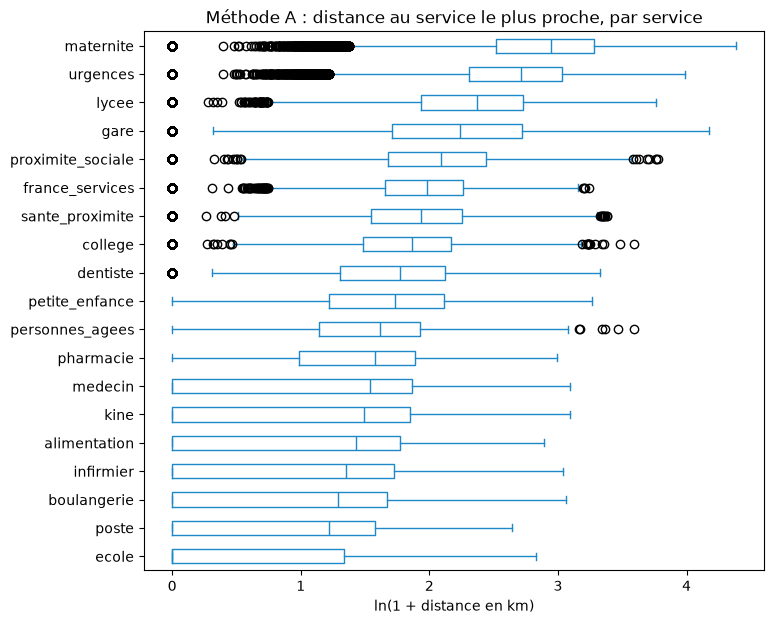

In [9]:
base_A = base.copy()   # le centre (x, y) est le centroïde du polygone
dist_A, _ = dist.distances_par_service(base_A, equipements, services)

assert dist_A.notna().all().all(), "Distance manquante."
assert (dist_A[presence.reindex(dist_A.index)].fillna(0) == 0).all().all(), "Une commune équipée a une distance non nulle."

resume_A = dsc.resume_par_service(dist_A)
display(resume_A.sort_values("mediane_km", ascending=False))

ordre = dist_A.median().sort_values().index
fig, ax = plt.subplots(figsize=(8, 7))
np.log1p(dist_A[ordre]).plot.box(vert=False, ax=ax, color=COULEURS["A"])
ax.set_xlabel("ln(1 + distance en km)")
ax.set_title("Méthode A : distance au service le plus proche, par service")
fig.savefig(FIGURES / "v5_boites_distances_A.png", dpi=150, bbox_inches="tight")
plt.show()

Les services se rangent en trois familles :

- **les services rares**, loin partout : médiane de 18,0 km pour la maternité, 14,0 km pour les urgences, 9,7 km pour le lycée, 8,4 km pour la gare ;
- **les services intermédiaires** (collège, dentiste, France Services, santé de proximité…) : médiane de 5 à 7 km ;
- **les services du quotidien**, proches : médiane de 2,4 km pour la poste, 2,6 km pour la boulangerie, 2,9 km pour l'infirmier, et 0 pour l'école (61 % des communes en ont une).

Pour chaque service, la moyenne est très proche de la médiane (3,79 et 3,85 km pour la pharmacie, 19,1 et 18,0 km pour la maternité) et le maximum vaut 4 à 9 fois la médiane. Les distances **entre communes** sont donc assez resserrées, sans longue queue : il n'y a pas une poignée de communes extrêmement plus éloignées que toutes les autres. Les inégalités se jouent surtout **entre services**.

### 2.3 La population éloignée (méthode A)

Compter des communes donne une image trompeuse, car la France compte beaucoup de très petites communes. On rapporte donc la **population** des communes situées à plus de 5, 10 ou 20 km d'un service à la population totale. Tous les habitants d'une commune sont supposés vivre à son point de départ, ici le centroïde.

In [10]:
pop = base.set_index("code")["population"]
eloignee_A = dsc.part_population_eloignee(dist_A, pop, SEUILS_KM)
display(eloignee_A.sort_values(eloignee_A.columns[0], ascending=False))

,> 5 km,> 10 km,> 20 km
maternite,53.07,35.80,13.87
urgences,48.56,29.48,7.03
lycee,32.69,15.21,1.72
france_services,29.92,5.68,0.03
gare,29.91,14.24,3.59
proximite_sociale,27.46,9.26,0.50
sante_proximite,21.17,4.45,0.12
college,15.79,1.87,0.03
dentiste,10.96,1.65,0.01
petite_enfance,10.37,1.89,0.03


Raisonner en habitants change l'image. Pour les services du quotidien, très peu de personnes sont loin : 0,46 % des habitants vivent à plus de 5 km d'une école, 1,3 % d'une poste, 2,2 % d'une boulangerie, environ 5,5 % d'un médecin ou d'une pharmacie. À l'inverse, **53,1 % des habitants vivent à plus de 5 km d'une maternité** (35,8 % à plus de 10 km, 13,9 % à plus de 20 km) et 48,6 % à plus de 5 km des urgences.

Ces pourcentages comptent toute la population pour chaque service : ils mesurent l'exposition à l'éloignement, pas le nombre de personnes qui ont réellement besoin du service (seules les femmes enceintes vont à la maternité).

### 2.4 L'indice A

,indice A
count,34788.000
mean,-0.000
std,0.712
min,-2.160
1%,-1.941
10%,-1.073
25%,-0.414
50%,0.161
75%,0.522
90%,0.778


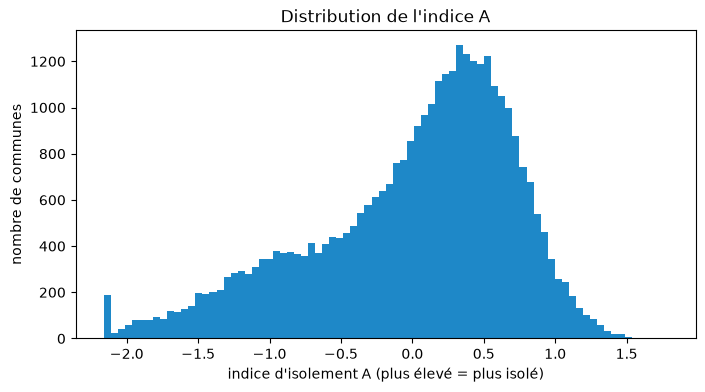

Communes plus isolées que la moyenne (indice > 0) : 59.0%, soit 9.9% de la population


,nom,population,surface_km2,indice
code,,,,
64542,Urdos,71,36.661530,1.785700
2B153,Manso,116,121.254632,1.762382
64136,Borce,112,58.272540,1.692086
05064,La Chapelle-en-Valgaudémar,120,127.505850,1.579194
09100,Couflens,100,56.355883,1.553541
38375,Saint-Christophe-en-Oisans,99,237.506235,1.536146
21237,Échalot,93,27.665546,1.535967
64316,Larrau,179,126.986982,1.528728
51371,Moivre,54,22.175960,1.526823


In [11]:
z_A = idx.standardiser(idx.log_distance(dist_A))
poids_A = idx.poids_egaux(services)
indice_A = idx.indice_pondere(z_A, poids_A).rename("A")

display(dsc.decrire_indice(indice_A).to_frame("indice A"))

fig, ax = plt.subplots(figsize=(8, 4))
indice_A.plot.hist(bins=80, ax=ax, color=COULEURS["A"])
ax.set_xlabel("indice d'isolement A (plus élevé = plus isolé)")
ax.set_ylabel("nombre de communes")
ax.set_title("Distribution de l'indice A")
fig.savefig(FIGURES / "v5_histogramme_A.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Communes plus isolées que la moyenne (indice > 0) : {(indice_A > 0).mean():.1%}, "
      f"soit {pop[indice_A > 0].sum() / pop.sum():.1%} de la population")
display(dsc.communes_les_plus_isolees(base, indice_A, n=15))

L'indice A a une moyenne nulle par construction et un écart-type de 0,71. Sa distribution est **asymétrique vers la gauche** : la médiane (0,16) est au-dessus de la moyenne, et la queue la plus longue est du côté des communes très bien desservies (minimum −2,16, maximum 1,79). La majorité des communes sont un peu plus isolées que la moyenne, et une minorité de villes très bien équipées tire la moyenne vers le bas.

**59 % des communes ont un indice positif, mais elles ne regroupent que 9,9 % de la population** : les communes isolées sont nombreuses mais peu peuplées. Les communes les plus isolées sont de très petits villages (35 à 179 habitants) des Pyrénées (Urdos, Borce, Larrau, Couflens, Mantet), des Alpes (La Chapelle-en-Valgaudémar, Saint-Christophe-en-Oisans), de Corse (Manso, Osani), mais aussi des plateaux de Bourgogne (Échalot, Poiseul-la-Grange) et de Champagne (Moivre, Herpont).

## Partie 3. Méthode B : chef-lieu, distance réelle et poids experts

### 3.1 Principe

La méthode B change **trois** choses par rapport à A, et seulement trois.

**1. Le point de départ est le chef-lieu.** L'IGN fournit dans Admin Express la position du chef-lieu de chaque commune (couche `chef_lieu_de_commune`) et de chaque arrondissement municipal : c'est en pratique l'emplacement de la mairie, au cœur du bourg principal. Historiquement, le bourg s'est construit autour de la mairie et de l'église ; c'est là que vit la plus grande partie des habitants et que se trouvent les rares commerces. Mesurer depuis ce point rapproche la mesure de l'expérience réelle des habitants.

**2. La distance n'est jamais mise à 0 : on enlève l'indicatrice de présence.** Avec le centroïde, l'indicatrice était nécessaire : le centroïde est un point arbitraire, et mesurer la distance d'un point au hasard à la pharmacie de la commune n'a pas de sens. On décidait donc qu'un service présent dans la commune était « à distance 0 ». Le chef-lieu, lui, est un vrai lieu de vie : la distance de la mairie à la pharmacie la plus proche **a un sens même si cette pharmacie est dans la commune**. Dans une grande commune dont la pharmacie est dans un hameau à 4 km du bourg, les habitants du bourg font réellement 4 km. On mesure donc toujours la distance réelle :

$$d_{c,s}^{B} \;=\; \min_{e\,\in\,\mathcal{E}_s} \big\lVert x_c^{B} - x_e \big\rVert \qquad \text{(au lieu de } \mathbf{1}[n_{c,s}=0] \times \min_e \lVert x_c^{A} - x_e \rVert \text{ en A)}$$

Une conséquence est à garder en tête : les équipements sans coordonnées (0,4 % du panier) ne comptent plus du tout en B, puisque la présence n'est plus utilisée. Une commune dont le seul équipement d'un service n'est pas géolocalisé se voit attribuer la distance au plus proche équipement localisé, éventuellement dans une commune voisine.

**3. Les services sont pondérés selon leur importance.** Chaque service est noté sur trois critères :

| Critère | Notes |
|---|---|
| **E** : essentialité | 2 = vital ou obligatoire, 1 = important, 0 = confort |
| **F** : fréquence d'usage | 2 = quotidien ou hebdomadaire, 1 = mensuel à quelques fois par an, 0 = rare |
| **P** : public concerné | 1 = presque toute la population, 0 = un public particulier |

Le score et le poids du service $s$ sont :

$$\text{score}_s \;=\; 1 + E_s + F_s + P_s \;\in\; [1, 6] \qquad\qquad w_s^{B} \;=\; \frac{\text{score}_s}{\sum_{k=1}^{19} \text{score}_k}$$

Le « +1 » garantit qu'aucun service n'a un poids nul.

**L'indice B** reprend les étapes 2 et 3 de la méthode A (logarithme, standardisation) sur la distance $d_{c,s}^{B}$ (depuis le chef-lieu, sans indicatrice), puis fait la moyenne avec les poids $w_s^{B}$ :

$$\boxed{\;I_c^{B} \;=\; \sum_{s=1}^{19} w_s^{B}\, z_{c,s}^{B} \;=\; \frac{\sum_{s} \left(1 + E_s + F_s + P_s\right)\, z_{c,s}^{B}}{\sum_{s} \left(1 + E_s + F_s + P_s\right)}\;}$$

où $z_{c,s}^{B}$ est la distance $d_{c,s}^{B}$ passée au logarithme puis standardisée, exactement comme en 2.1.

,E,F,P,score,poids,justification
alimentation,2,2,1,6,0.0811,"se nourrir, plusieurs fois par semaine, pour tous"
boulangerie,1,2,1,5,0.0676,"commerce le plus fréquenté, en partie substitu..."
pharmacie,2,1,1,5,0.0676,"seul accès aux médicaments, recours régulier"
medecin,2,1,1,5,0.0676,"porte d'entrée du soin (médecin traitant), pou..."
ecole,2,2,0,5,0.0676,"obligatoire dès 3 ans, trajet quotidien, familles"
college,2,2,0,5,0.0676,"obligatoire, trajet quotidien, 11-15 ans"
poste,1,1,1,4,0.0541,"courrier, colis, services bancaires de base"
petite_enfance,1,2,0,4,0.0541,"garde d'enfant, condition de l'emploi des parents"
sante_proximite,1,1,1,4,0.0541,centre ou maison de santé : soins de premier r...
urgences,2,0,1,4,0.0541,"vital (AVC, infarctus) mais recours rare"


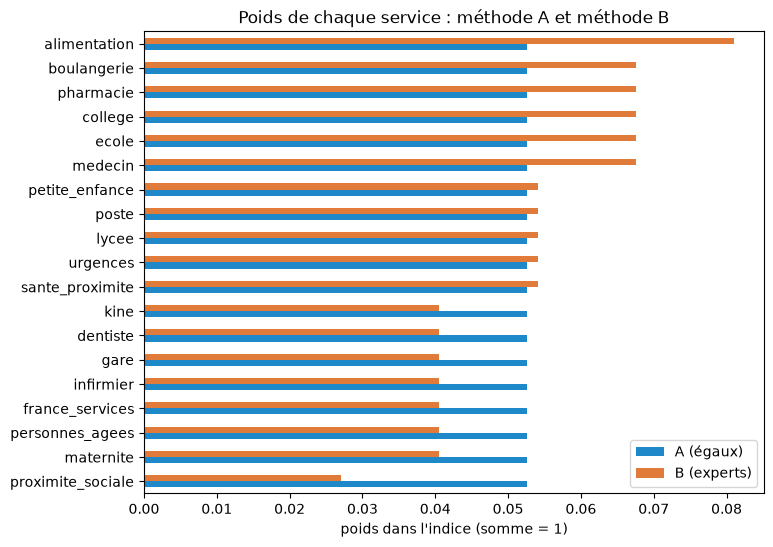

Poids de chaque thème :


,commerces,enseignement,sante,services_publics,transport
A (égaux),0.105,0.158,0.421,0.263,0.053
B (experts),0.149,0.189,0.405,0.216,0.041


In [12]:
grille = idx.table_grille_experte(services)
display(grille.sort_values("score", ascending=False))

poids_B = idx.poids_experts(services)
comparaison_poids = pd.DataFrame({
    "A (égaux)": pd.Series(poids_A) / sum(poids_A.values()),
    "B (experts)": pd.Series(poids_B) / sum(poids_B.values()),
}).sort_values("B (experts)")

fig, ax = plt.subplots(figsize=(8, 6))
comparaison_poids.plot.barh(ax=ax, color=[COULEURS["A"], COULEURS["B"]])
ax.set_xlabel("poids dans l'indice (somme = 1)")
ax.set_title("Poids de chaque service : méthode A et méthode B")
fig.savefig(FIGURES / "v5_poids_A_B.png", dpi=150, bbox_inches="tight")
plt.show()

themes = pd.Series(idx.THEMES)
print("Poids de chaque thème :")
display(comparaison_poids.groupby(themes).sum().round(3).T)

La grille donne le poids le plus fort à l'**alimentation** (score 6 : vitale, quotidienne, pour tous), puis aux services vitaux ou quotidiens (boulangerie, pharmacie, médecin, école, collège : score 5). Les services les moins pondérés sont la **proximité sociale** (score 2) et, au score 3, la gare, le dentiste, la maternité, l'infirmier, le kiné, France Services et l'aide aux personnes âgées. Le poids le plus fort (8,1 %) est trois fois le plus faible (2,7 %), alors qu'en A tous valent 5,3 %.

Au niveau des thèmes, les écarts sont plus faibles qu'on pourrait le penser : la santé passe de 42 % à 40 %, les commerces de 11 % à 15 %, l'enseignement de 16 % à 19 %, les services publics et sociaux de 26 % à 22 % et la gare de 5 % à 4 %. **Les poids experts redistribuent surtout à l'intérieur des thèmes** (le médecin pèse plus que le kiné) plutôt qu'entre eux. On peut donc s'attendre à ce que ce changement modifie peu le classement des communes.

### 3.2 Le point de départ : centroïde ou chef-lieu ?

`cm.lire_chefs_lieux` lit les deux couches ponctuelles de l'IGN, et `cm.centres_chef_lieu` remplace le centroïde de chaque commune par son chef-lieu. Si une commune n'a pas de chef-lieu dans la couche, on garde son centroïde et on le signale. On calcule au passage l'**écart** entre les deux points, en km.

Journal : {'communes': 34788, 'sans_chef_lieu (centroïde gardé)': 6, 'codes_sans_chef_lieu': ['55039', '55050', '55139', '55189', '55239', '55307']}


,count,mean,std,min,25%,50%,75%,90%,99%,max
écart centroïde - chef-lieu (km),34788.0,0.93,0.75,0.0,0.45,0.75,1.19,1.76,3.73,14.7


Communes où l'écart dépasse 2 km : 7.0% ; 5 km : 0.4%


Spearman écart / surface : 0.48


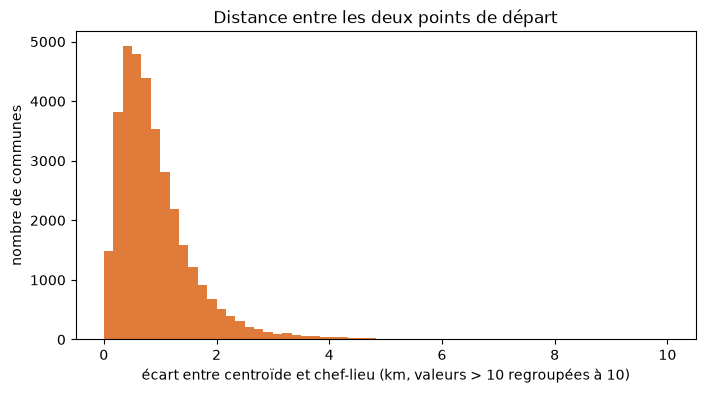

,nom,population,surface_km2,ecart_centre_km
code,,,,
13004,Arles,51811,757.1,14.7
2B301,San-Gavino-di-Tenda,64,50.6,11.0
64320,Laruns,1177,248.7,10.6
65059,Bagnères-de-Bigorre,7114,126.1,10.5
09024,Aston,197,154.2,10.4
65465,Vielle-Aure,315,35.4,10.2
66005,Angoustrine-Villeneuve-des-Escaldes,542,87.3,9.5
33229,Lanton,7337,137.6,9.3
2B314,Santo-Pietro-di-Tenda,341,126.1,8.7


In [13]:
chefs = cm.lire_chefs_lieux(CHEMIN_GPKG)
base_B, journal_cl = cm.centres_chef_lieu(base, chefs)
print("Journal :", journal_cl)

ecart = base_B.set_index("code")["ecart_centre_km"]
display(ecart.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(2).to_frame("écart centroïde - chef-lieu (km)").T)
print(f"Communes où l'écart dépasse 2 km : {(ecart > 2).mean():.1%} ; 5 km : {(ecart > 5).mean():.1%}")
surface = base.set_index("code")["surface_km2"]
print(f"Spearman écart / surface : {an.correlation_spearman(ecart, surface)['rho']:.2f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(ecart.clip(upper=10), bins=60, color=COULEURS["B"])
ax.set_xlabel("écart entre centroïde et chef-lieu (km, valeurs > 10 regroupées à 10)")
ax.set_ylabel("nombre de communes")
ax.set_title("Distance entre les deux points de départ")
fig.savefig(FIGURES / "v5_ecart_centres.png", dpi=150, bbox_inches="tight")
plt.show()

top_ecart = (base_B.set_index("code")[["nom", "population", "surface_km2", "ecart_centre_km"]]
             .sort_values("ecart_centre_km", ascending=False))
display(top_ecart.head(10).round(1))

Pour voir concrètement ce que change le point de départ, on dessine trois communes où l'écart est le plus grand parmi celles de plus de 1 000 habitants : le polygone, le centroïde (méthode A, en bleu) et le chef-lieu (méthode B, en orange).

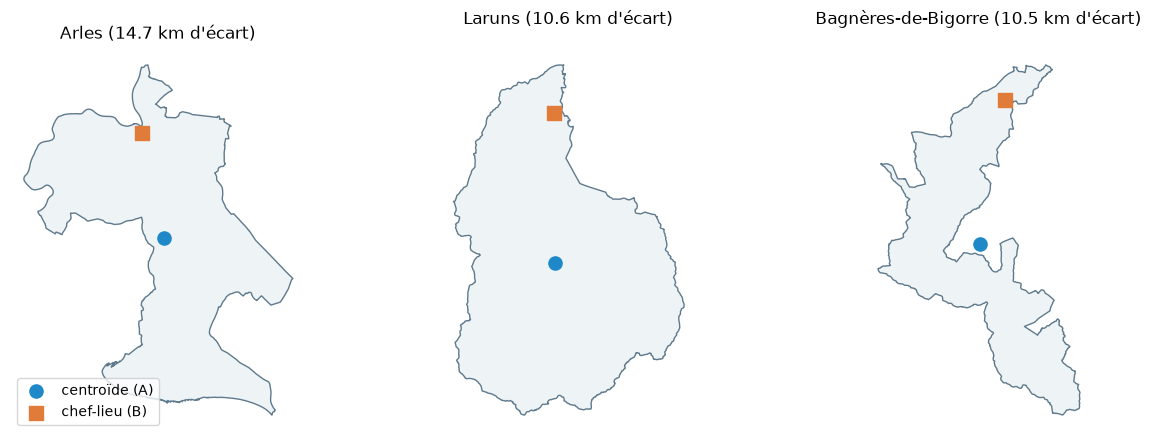

In [14]:
exemples = top_ecart[top_ecart["population"] > 1000].head(3).index
pts_A = base_A.set_index("code")
pts_B = base_B.set_index("code")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, code_c in zip(axes, exemples):
    geo[geo["code"] == code_c].plot(ax=ax, color="#EEF3F6", edgecolor="#5f7a8c")
    ax.scatter(pts_A.loc[code_c, "x"], pts_A.loc[code_c, "y"], s=90, color=COULEURS["A"], label="centroïde (A)", zorder=3)
    ax.scatter(pts_B.loc[code_c, "x"], pts_B.loc[code_c, "y"], s=90, color=COULEURS["B"], marker="s", label="chef-lieu (B)", zorder=3)
    ax.set_title(f"{pts_A.loc[code_c, 'nom']} ({top_ecart.loc[code_c, 'ecart_centre_km']:.1f} km d'écart)")
    ax.set_axis_off()
axes[0].legend(loc="lower left")
fig.savefig(FIGURES / "v5_exemples_centres.png", dpi=150, bbox_inches="tight")
plt.show()

Le chef-lieu est trouvé pour toutes les communes sauf **6**, toutes dans la Meuse (codes 55039, 55050…) : ce sont des villages détruits pendant la bataille de Verdun et jamais reconstruits, sans habitant ni mairie. On garde leur centroïde.

**Dans la plupart des communes, les deux points sont proches** : l'écart médian est de 750 m, et 90 % des communes ont un écart inférieur à 1,8 km. Mais 7 % des communes ont un écart supérieur à 2 km, et 125 communes (0,4 %) un écart supérieur à 5 km. L'écart augmente avec la surface (Spearman de 0,48).

Les exemples montrent les cas typiques. À **Arles**, la plus grande commune de France métropolitaine (757 km², dont une grande partie de la Camargue), le centroïde tombe au milieu des marais, à 14,7 km de la ville. À **Laruns** et **Bagnères-de-Bigorre**, communes de montagne, le centroïde est en haute vallée ou sur les sommets, alors que le bourg est en bas. Dans ces communes, mesurer depuis le centroïde revient à mesurer l'éloignement d'un endroit où personne n'habite.

### 3.3 Les distances de la méthode B

On relance le calcul avec les chefs-lieux comme points de départ et sans la règle de présence (`regle_presence=False`). Toutes les communes sont concernées : celles qui n'ont pas le service (le point de départ change) et celles qui l'ont (la distance n'est plus 0 mais la distance réelle de la mairie à l'équipement).

In [15]:
dist_B, _ = dist.distances_par_service(base_B, equipements, services, regle_presence=False)
assert dist_B.notna().all().all()

# Pour les communes qui POSSÈDENT le service : à quelle distance de la mairie est-il vraiment ?
equipees = presence.reindex(dist_B.index)
interne = pd.DataFrame({
    "communes_equipees": equipees.sum(),
    "mediane_km": dist_B.where(equipees).median(),
    "q90_km": dist_B.where(equipees).quantile(0.9),
    "part_a_plus_de_1km_%": (dist_B.where(equipees) > 1).sum() / equipees.sum() * 100,
}).round(2).sort_values("mediane_km", ascending=False)
print("Communes qui ont le service : distance réelle de la mairie à l'équipement le plus proche")
display(interne)

ecart_d = dist_B - dist_A
changement = pd.DataFrame({
    "mediane_A_km": dist_A.median(),
    "mediane_B_km": dist_B.median(),
    "moyenne_A_km": dist_A.mean(),
    "moyenne_B_km": dist_B.mean(),
    "B_plus_proche_%": (ecart_d < -0.01).mean() * 100,
    "B_plus_loin_%": (ecart_d > 0.01).mean() * 100,
}).round(2).sort_values("mediane_A_km", ascending=False)
display(changement)

eloignee_B = dsc.part_population_eloignee(dist_B, pop, SEUILS_KM)
print("Part de la population à plus de 10 km, selon le point de départ :")
display(pd.DataFrame({"A (centroïde)": eloignee_A["> 10 km"], "B (chef-lieu)": eloignee_B["> 10 km"]})
        .sort_values("A (centroïde)", ascending=False).T)

Communes qui ont le service : distance réelle de la mairie à l'équipement le plus proche


,communes_equipees,mediane_km,q90_km,part_a_plus_de_1km_%
maternite,381,1.20,2.69,61.42
urgences,568,1.06,2.37,52.82
gare,2563,0.64,1.62,25.13
lycee,1480,0.57,1.56,25.47
college,3874,0.46,1.09,12.31
proximite_sociale,2506,0.34,1.32,17.92
sante_proximite,3436,0.31,1.06,11.03
petite_enfance,6584,0.31,1.04,10.69
dentiste,5840,0.23,0.76,5.91
personnes_agees,6953,0.23,0.84,7.58


,mediane_A_km,mediane_B_km,moyenne_A_km,moyenne_B_km,B_plus_proche_%,B_plus_loin_%
maternite,17.99,17.97,19.08,19.02,52.12,46.57
urgences,14.04,14.00,14.75,14.68,52.25,46.39
lycee,9.66,9.58,10.47,10.41,51.61,47.10
gare,8.35,8.26,10.16,10.11,50.80,47.86
proximite_sociale,7.09,6.99,7.73,7.66,51.10,47.45
france_services,6.28,6.18,6.43,6.34,51.77,46.53
sante_proximite,5.92,5.80,6.29,6.21,50.43,48.18
college,5.43,5.30,5.66,5.58,51.02,47.67
dentiste,4.87,4.70,5.15,5.07,47.97,50.78
petite_enfance,4.68,4.51,5.06,5.02,46.37,52.26


Part de la population à plus de 10 km, selon le point de départ :


,maternite,urgences,lycee,gare,proximite_sociale,france_services,sante_proximite,petite_enfance,college,dentiste,personnes_agees,kine,medecin,pharmacie,infirmier,alimentation,boulangerie,poste,ecole
A (centroïde),35.80,29.48,15.21,14.24,9.26,5.68,4.45,1.89,1.87,1.65,0.38,0.30,0.21,0.19,0.09,0.08,0.05,0.01,0.0
B (chef-lieu),35.46,29.20,14.85,14.08,9.14,5.60,4.41,1.84,1.75,1.55,0.33,0.27,0.18,0.16,0.07,0.07,0.04,0.01,0.0


**Que se passe-t-il pour les communes qui ont le service ?** Le premier tableau répond à la question que l'indicatrice de A masquait. Pour les services du quotidien, l'équipement de la commune est en général tout près de la mairie : distance médiane de 80 m pour la poste, 120 m pour l'école, 140 m pour la boulangerie, 180 m pour la pharmacie. Moins de 10 % des communes équipées ont leur boulangerie ou leur épicerie à plus de 1 km de la mairie. Mettre ces distances à 0, comme le fait A, est donc une bonne approximation pour les services de proximité.

Ce n'est plus vrai pour les grands équipements. Dans les communes qui ont une maternité ou des urgences, l'hôpital est à 1,1 à 1,2 km de la mairie (distance médiane), et à plus de 1 km dans plus de la moitié des cas. Les hôpitaux, les gares et les lycées sont souvent en périphérie de la ville. La méthode B en tient compte, la méthode A non.

**Pour l'ensemble des communes**, les distances médianes changent peu entre A et B : elles baissent un peu pour les services qui manquent à la plupart des communes (de −0,02 km pour la maternité à −0,3 km pour la poste), car le chef-lieu, au cœur du bourg, est en général mieux placé que le centroïde par rapport aux bourgs voisins équipés. La seule exception est l'école, dont la médiane passe de 0 à 0,29 km : 61 % des communes en ont une, et sa distance n'est plus mise à 0. La part de la population à plus de 10 km d'un service baisse légèrement (de 35,8 % à 35,5 % pour la maternité).

Pour les services rares, déplacer le point de départ de 1 km change peu une distance de 18 km. C'est pour les **services du quotidien**, à 2 ou 3 km, que le choix du point de départ pèse le plus.

### 3.4 L'indice B

,indice A,indice B
count,34788.000,34788.000
mean,-0.000,-0.000
std,0.712,0.716
min,-2.160,-2.057
1%,-1.941,-1.756
10%,-1.073,-1.066
25%,-0.414,-0.479
50%,0.161,0.129
75%,0.522,0.536
90%,0.778,0.832


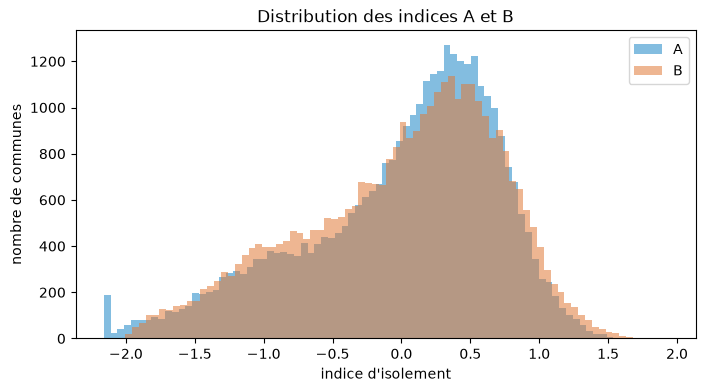

Communes plus isolées que la moyenne (indice B > 0) : 56.6%, soit 9.4% de la population


,nom,population,surface_km2,indice
code,,,,
2B153,Manso,116,121.254632,1.930587
51371,Moivre,54,22.175960,1.694517
21237,Échalot,93,27.665546,1.692516
43054,Chanaleilles,173,48.545553,1.675507
05064,La Chapelle-en-Valgaudémar,120,127.505850,1.663937
51292,Herpont,121,23.025783,1.651170
64542,Urdos,71,36.661530,1.648638
21489,Poiseul-la-Grange,75,23.070117,1.638980
2A197,Osani,96,51.664285,1.634040


In [16]:
z_B = idx.standardiser(idx.log_distance(dist_B))
indice_B = idx.indice_pondere(z_B, poids_B).rename("B")

display(pd.concat([dsc.decrire_indice(indice_A).rename("indice A"),
                   dsc.decrire_indice(indice_B).rename("indice B")], axis=1))

fig, ax = plt.subplots(figsize=(8, 4))
indice_A.plot.hist(bins=80, ax=ax, color=COULEURS["A"], alpha=0.55, label="A")
indice_B.plot.hist(bins=80, ax=ax, color=COULEURS["B"], alpha=0.55, label="B")
ax.set_xlabel("indice d'isolement")
ax.set_ylabel("nombre de communes")
ax.set_title("Distribution des indices A et B")
ax.legend()
fig.savefig(FIGURES / "v5_histogramme_A_B.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Communes plus isolées que la moyenne (indice B > 0) : {(indice_B > 0).mean():.1%}, "
      f"soit {pop[indice_B > 0].sum() / pop.sum():.1%} de la population")
display(dsc.communes_les_plus_isolees(base, indice_B, n=15))

Les deux indices ont des distributions proches (écart-type 0,72 pour B et 0,71 pour A). B est un peu plus étalé vers le haut : son maximum est de 1,93, contre 1,79 pour A. **56,6 % des communes ont un indice B positif, pour 9,4 % de la population** (59,0 % et 9,9 % avec A).

Le haut du classement se recompose. Manso (Corse) prend la première place. Les villages de montagne restent présents (La Chapelle-en-Valgaudémar, Urdos, Osani), mais plusieurs autres reculent : Borce, Couflens, Larrau et Saint-Christophe-en-Oisans sortent du top 15. Les villages de plateau du Nord-Est gagnent des places : Champagne (Moivre, Herpont, Le Fresne, Minaucourt), Bourgogne (Échalot, Poiseul-la-Grange), Yonne (Arthonnay), Haute-Marne (Germay). Dans ces villages, le bourg est petit et loin de tout ; centroïde et chef-lieu y sont proches, si bien que le changement de point de départ ne les avantage pas. En montagne au contraire, le chef-lieu en fond de vallée les rapproche des services.

### 3.5 Une lecture en kilomètres

Un indice standardisé est commode pour classer, mais il ne parle pas : que veut dire « 0,8 » ? On calcule donc aussi, avec les poids de B, la **distance moyenne pondérée** aux 19 services, en kilomètres :

$$D_c^{B} \;=\; \sum_{s=1}^{19} w_s^{B}\, d_{c,s}^{B} \qquad (\text{en km, sans logarithme ni standardisation})$$

et, pour comparaison, $D_c^{A} = \frac{1}{19}\sum_s d_{c,s}^{A}$ avec les poids égaux. Les deux formules se décomposent service par service : le terme $w_s\, d_{c,s}$ dit combien de kilomètres l'absence du service $s$ ajoute à $D_c$. C'est la distance « typique » à parcourir pour un panier de services où les besoins essentiels comptent plus. Elle n'est pas standardisée : les services rares, toujours lointains, y pèsent lourd, ce qui la rend plus sensible qu'un indice aux quelques services très éloignés.

In [17]:
w_B = pd.Series(poids_B)
km_B = (dist_B[w_B.index] * w_B).sum(axis=1) / w_B.sum()
km_A = dist_A.mean(axis=1)   # même calcul avec les poids égaux de A

lecture_km = pd.DataFrame({"A (km, poids égaux)": km_A.describe(percentiles=[0.1, 0.5, 0.9, 0.99]),
                           "B (km, poids experts)": km_B.describe(percentiles=[0.1, 0.5, 0.9, 0.99])}).round(2)
display(lecture_km)
print(f"Distance moyenne pondérée vécue par l'habitant moyen (pondération par la population) : "
      f"A = {np.average(km_A, weights=pop.reindex(km_A.index)):.2f} km ; "
      f"B = {np.average(km_B, weights=pop.reindex(km_B.index)):.2f} km")
print(f"Spearman entre l'indice B et sa version en km : {an.correlation_spearman(indice_B, km_B)['rho']:.3f}")

,"A (km, poids égaux)","B (km, poids experts)"
count,34788.00,34788.00
mean,6.21,5.75
std,2.79,2.59
min,0.00,0.19
10%,2.58,2.38
50%,6.18,5.69
90%,9.77,9.09
99%,13.20,12.34
max,21.90,17.89


Distance moyenne pondérée vécue par l'habitant moyen (pondération par la population) : A = 2.25 km ; B = 2.24 km
Spearman entre l'indice B et sa version en km : 0.937


La lecture en kilomètres donne un ordre de grandeur concret. Avec la méthode B, **la commune médiane est à 5,7 km en moyenne pondérée de ses services**, une commune sur dix à plus de 9,1 km, et la plus isolée (Manso) à 17,9 km. Aucune commune n'est à 0 km : même une grande ville a ses services à quelques centaines de mètres de sa mairie (le minimum est de 0,19 km).

Rapporté aux habitants, l'ordre de grandeur est plus faible : **l'habitant moyen est à 2,2 km** (2,24 km avec B, 2,25 km avec A). Les deux méthodes donnent presque le même chiffre, pour deux raisons qui se compensent. B mesure une distance réelle dans les villes, là où A met 0, ce qui augmente la distance. Mais B part du bourg plutôt que du centroïde dans les communes non équipées, ce qui la diminue.

Cette distance en km classe les communes presque comme l'indice B (Spearman de 0,94). L'écart vient de la standardisation : en km, les services rares (maternité, urgences) pèsent beaucoup plus, puisque leurs distances sont les plus grandes. On garde l'indice standardisé pour classer, et le km pour donner un ordre de grandeur.

## Partie 4. Méthode C : six grands besoins

### 4.1 Principe

A et B résument 19 services. Ce choix a un défaut : **un thème pèse d'autant plus qu'il compte de services**. La santé en compte 8 sur 19 et pèse donc 42 % de l'indice A, alors que la gare, seule de son thème, pèse 5 %. Les poids experts de B corrigent un peu ce déséquilibre service par service, sans le supprimer (la santé y pèse encore 40 %).

La méthode C raisonne autrement : un habitant n'a pas 19 besoins, mais **quelques grands besoins**, chacun pouvant être satisfait par un ou plusieurs services. On regroupe donc les 19 services en **6 besoins**, en suivant la nomenclature de la BPE elle-même (domaines A à E et leurs sous-domaines) :

| Besoin | Services | Sous-domaines BPE | Règle |
|---|---|---|---|
| **Faire ses courses** | boulangerie, alimentation | B1, B2 : grandes surfaces, commerces alimentaires | **minimum** |
| **Se soigner au quotidien** | médecin, pharmacie, infirmier, kiné, dentiste, santé de proximité | D1 (centres et maisons de santé), D2 (professions libérales), D3 (pharmacie) | moyenne |
| **Soins hospitaliers** | urgences, maternité | D1 : établissements de santé | moyenne |
| **Scolariser ses enfants** | école, collège, lycée | C1, C2, C3 : premier et second degrés | moyenne |
| **Démarches et accompagnement social** | poste, France Services, petite enfance, personnes âgées, proximité sociale | A1, A2 (services publics et généraux), D4, D5 (action sociale) | moyenne |
| **Se déplacer** | gare | E1 : infrastructures de transport | — |

Deux choix méritent d'être expliqués :
- **Urgences et maternité sont séparées des soins courants**, alors qu'elles relèvent toutes du domaine santé. On n'y va pas pour les mêmes raisons ni au même rythme, et elles sont 20 à 50 fois plus rares : les mélanger reviendrait à noyer l'accès au médecin dans l'éloignement de l'hôpital.
- **La règle diffère selon le besoin.** Pour faire ses courses, la boulangerie et la supérette sont **substituables** : on peut acheter du pain au supermarché. La distance au besoin est donc la distance au plus proche des deux. Pour les autres besoins, les services sont **complémentaires** : un pharmacien ne remplace pas un médecin, et un collège ne remplace pas une école. On prend donc la moyenne des distances.

**Formules.** Pour la commune $c$ et le besoin $g$, à partir des distances $d_{c,s}^{B}$ de la méthode B (chef-lieu, sans indicatrice) :

$$D_{c,g} \;=\; \begin{cases} \displaystyle\min_{s\,\in\,g}\; d_{c,s}^{B} & \text{si les services de } g \text{ sont substituables (courses)} \\[2ex] \displaystyle\frac{1}{|g|}\sum_{s\,\in\,g} d_{c,s}^{B} & \text{sinon} \end{cases}$$

Puis, exactement comme pour A et B, on prend le logarithme et on standardise, **besoin par besoin**, avant de faire la moyenne des 6 besoins, chacun pesant autant :

$$z_{c,g} = \frac{\ln(1 + D_{c,g}) - \overline{\ln(1+D_{g})}}{\sigma_g} \qquad\qquad \boxed{\;I_c^{C} \;=\; \frac{1}{6}\sum_{g=1}^{6} z_{c,g}\;}$$

C ne change donc qu'une chose par rapport à B : la façon d'agréger les 19 distances (6 besoins à poids égaux au lieu de 19 services pondérés). Le point de départ et la distance sont ceux de B.

In [18]:
besoins = idx.BESOINS
table_besoins = pd.DataFrame({
    "besoin": [b["libelle"] for b in besoins.values()],
    "services": [", ".join(b["services"]) for b in besoins.values()],
    "nombre": [len(b["services"]) for b in besoins.values()],
    "regle": [b["regle"] for b in besoins.values()],
    "poids_dans_C_%": round(100 / len(besoins), 1),
}, index=list(besoins))
# Poids de chaque besoin dans A et B (somme des poids de ses services)
service_vers_besoin = {s: g for g, b in besoins.items() for s in b["services"]}
assert sorted(service_vers_besoin) == sorted(services), "Un service n'est dans aucun besoin, ou dans deux."
table_besoins["poids_dans_A_%"] = (comparaison_poids["A (égaux)"].groupby(service_vers_besoin).sum() * 100).round(1)
table_besoins["poids_dans_B_%"] = (comparaison_poids["B (experts)"].groupby(service_vers_besoin).sum() * 100).round(1)
display(table_besoins)

,besoin,services,nombre,regle,poids_dans_C_%,poids_dans_A_%,poids_dans_B_%
courses,Faire ses courses,"boulangerie, alimentation",2,min,16.7,10.5,14.9
soins_courants,Se soigner au quotidien,"medecin, pharmacie, infirmier, kine, dentiste,...",6,moyenne,16.7,31.6,31.1
hopital,Soins hospitaliers,"urgences, maternite",2,moyenne,16.7,10.5,9.5
scolarite,Scolariser ses enfants,"ecole, college, lycee",3,moyenne,16.7,15.8,18.9
social,Démarches et accompagnement social,"poste, france_services, petite_enfance, person...",5,moyenne,16.7,26.3,21.6
transport,Se déplacer,gare,1,moyenne,16.7,5.3,4.1


Le tableau montre ce que change le regroupement. Dans A et B, **se soigner au quotidien** pesait près d'un tiers de l'indice (31,6 % et 31,1 %) parce qu'il réunit 6 services, et **les démarches et l'accompagnement social** plus d'un cinquième (26,3 % et 21,6 %). À l'inverse, **la gare** ne pesait que 5,3 % (A) et 4,1 % (B), et **l'hôpital** environ 10 %. Dans C, chaque besoin pèse 16,7 %. Le transport voit donc son poids multiplié par 3 à 4, l'hôpital par 1,6 à 1,8, tandis que les soins courants sont divisés par deux.

C est donc la méthode qui donne **le plus de place aux équipements rares** (gare, hôpital). C'est un choix assumé : chaque grand besoin de la vie courante compte autant, quel que soit le nombre de types d'équipements que la BPE utilise pour le décrire.

### 4.2 Les groupes ont-ils du sens ?

Un regroupement n'a de sens statistique que si les services d'un même besoin **varient ensemble** : une commune loin du médecin devrait aussi être plutôt loin de l'infirmier. On le vérifie avec la matrice des corrélations entre les 19 distances standardisées $z_{c,s}^{B}$, rangées besoin par besoin. Si les groupes sont cohérents, on doit voir des **carrés plus foncés sur la diagonale** (corrélations fortes à l'intérieur d'un besoin) que dans le reste de la matrice.

Le tableau qui suit résume, pour chaque besoin, la corrélation moyenne **entre ses propres services** et la corrélation moyenne **avec les services des autres besoins**. Un groupe est cohérent quand la première dépasse nettement la seconde.

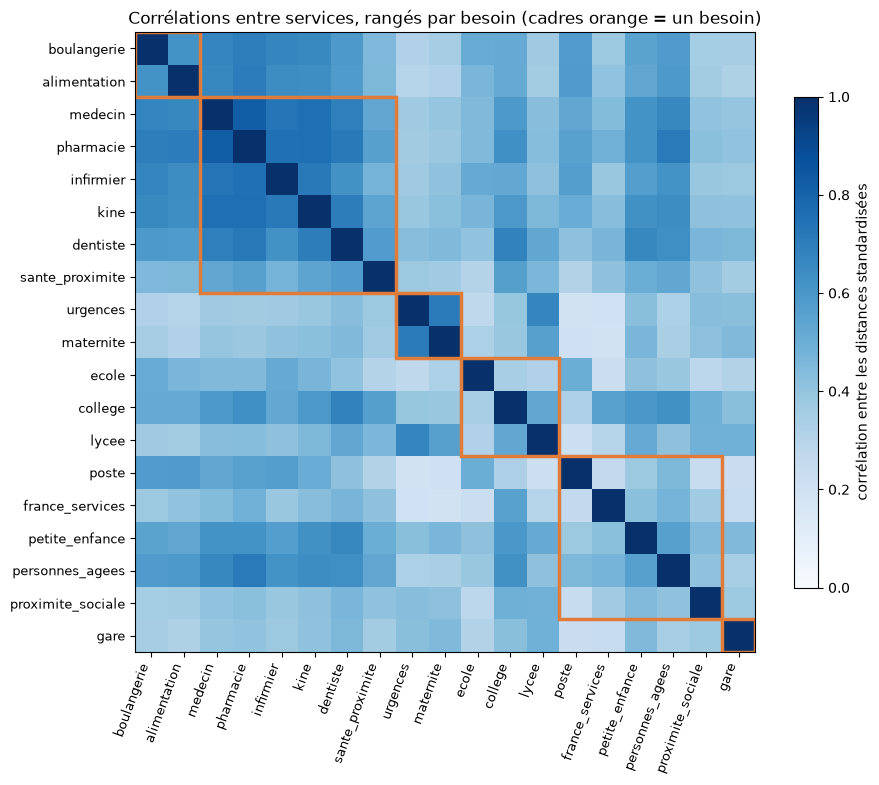

,services,corr_moyenne_interne,corr_moyenne_avec_les_autres,ecart
Faire ses courses,2.0,0.62,0.50,0.12
Se soigner au quotidien,6.0,0.66,0.50,0.17
Soins hospitaliers,2.0,0.71,0.37,0.34
Scolariser ses enfants,3.0,0.40,0.45,-0.06
Démarches et accompagnement social,5.0,0.40,0.45,-0.05
Se déplacer,1.0,NaN,0.38,NaN


In [19]:
ordre_services = [s for b in besoins.values() for s in b["services"]]
corr = z_B[ordre_services].corr()

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(ordre_services)))
ax.set_xticklabels(ordre_services, rotation=70, ha="right", fontsize=9)
ax.set_yticks(range(len(ordre_services)))
ax.set_yticklabels(ordre_services, fontsize=9)
debut = 0
for g, b in besoins.items():
    n = len(b["services"])
    ax.add_patch(plt.Rectangle((debut - 0.5, debut - 0.5), n, n, fill=False, edgecolor=COULEURS["B"], lw=2.5))
    debut += n
fig.colorbar(im, shrink=0.75, label="corrélation entre les distances standardisées")
ax.set_title("Corrélations entre services, rangés par besoin (cadres orange = un besoin)")
fig.savefig(FIGURES / "v5_correlations_besoins.png", dpi=150, bbox_inches="tight")
plt.show()

coherence = {}
for g, b in besoins.items():
    dedans = b["services"]
    dehors = [s for s in ordre_services if s not in dedans]
    bloc = corr.loc[dedans, dedans].to_numpy()
    intra = bloc[np.triu_indices(len(dedans), k=1)].mean() if len(dedans) > 1 else np.nan
    coherence[b["libelle"]] = {"services": len(dedans), "corr_moyenne_interne": intra,
                               "corr_moyenne_avec_les_autres": corr.loc[dedans, dehors].to_numpy().mean()}
coherence = pd.DataFrame(coherence).T
coherence["ecart"] = coherence["corr_moyenne_interne"] - coherence["corr_moyenne_avec_les_autres"]
display(coherence.round(2))

**Trois groupes sur cinq sont cohérents statistiquement, deux ne le sont pas.** (Le transport, avec un seul service, ne se teste pas.)

- **Soins hospitaliers** : le groupe le plus net. Urgences et maternité ont une corrélation de 0,71 entre elles, contre 0,37 avec le reste. Ce sont les mêmes hôpitaux.
- **Se soigner au quotidien** : 0,66 en interne contre 0,50 avec les autres. Le carré médecin, pharmacie, infirmier, kiné est le plus foncé de la matrice : ces professionnels s'installent dans les mêmes bourgs.
- **Faire ses courses** : 0,62 contre 0,50. La boulangerie et la supérette vont ensemble.
- **Scolariser ses enfants** et **Démarches et accompagnement social** : la corrélation interne (0,40) est **plus faible** que la corrélation avec les autres groupes (0,45). Leurs services sont de **rareté très différente**. L'école est présente dans 61 % des communes, le lycée dans 4 % ; la poste dans 40 %, France Services dans 7 %. Sur la matrice, le lycée ressemble davantage aux urgences qu'à l'école, et la poste davantage à la boulangerie qu'à France Services.

Autrement dit, les distances aux services s'organisent d'abord selon **leur rareté** (proximité ou équipement rare) et seulement ensuite selon **le thème**. Nos groupes sont construits par thème, pas par rareté. Ces deux groupes restent défendables comme besoins (scolariser un enfant de 3 à 18 ans demande d'accéder à l'école, puis au collège, puis au lycée), mais il faut garder en tête que leur distance moyenne mélange un équipement proche et un équipement lointain.

### 4.3 Les distances aux six besoins

On calcule $D_{c,g}$ avec `idx.distances_par_besoin`, puis on décrit chaque besoin : distance médiane et extrêmes, part de la population éloignée, et carte.

,mediane_km,moyenne_km,q90_km,q99_km,max_km,part_pop_plus_de_10km_%
Soins hospitaliers,16.50,16.85,27.52,36.61,59.77,34.13
Se déplacer,8.26,10.11,21.09,33.56,67.31,14.08
Scolariser ses enfants,5.56,5.80,9.82,14.34,24.54,1.13
Démarches et accompagnement social,5.00,5.04,8.05,11.09,18.42,0.22
Se soigner au quotidien,4.05,4.15,7.38,10.93,17.78,0.12
Faire ses courses,1.95,2.21,5.10,7.90,13.18,0.01


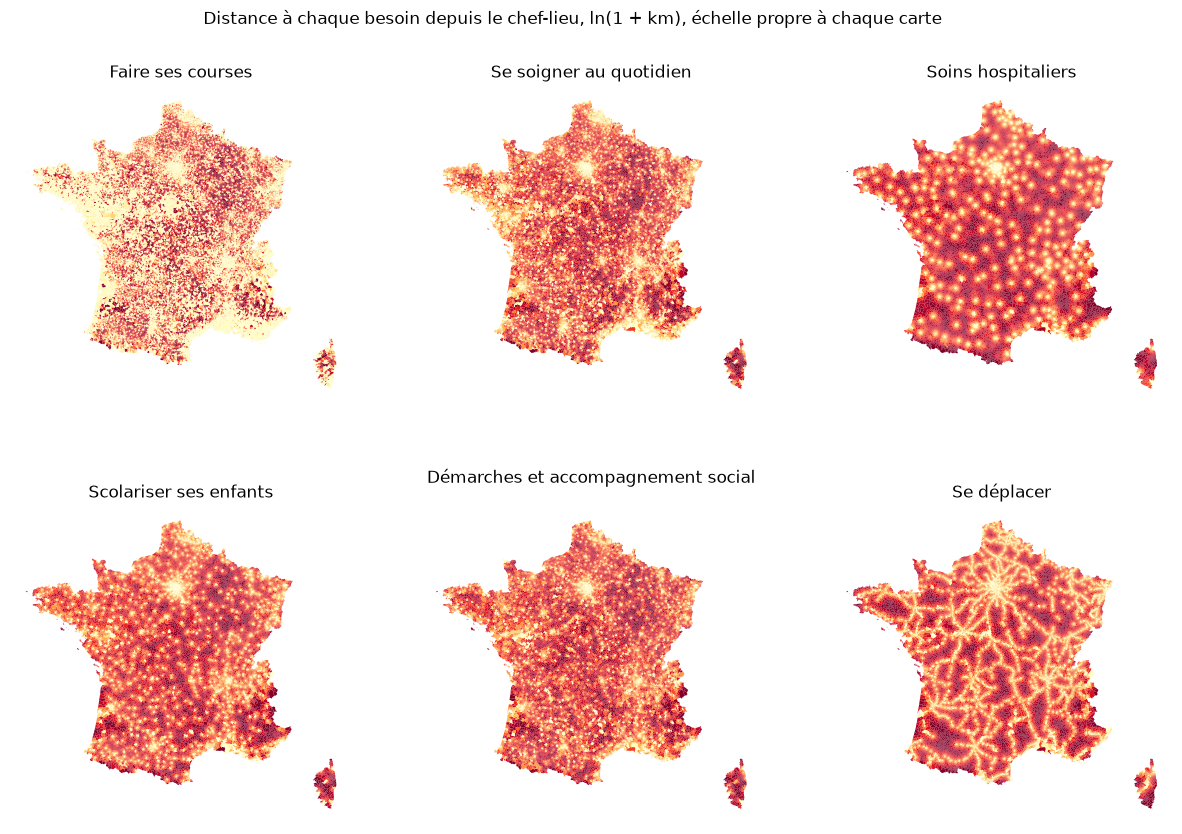

In [20]:
dist_C = idx.distances_par_besoin(dist_B, besoins)
noms_besoins = {g: b["libelle"] for g, b in besoins.items()}

resume_C = dsc.resume_par_service(dist_C).drop(columns="communes_equipees_%")
resume_C["part_pop_plus_de_10km_%"] = dsc.part_population_eloignee(dist_C, pop, [10])["> 10 km"]
display(resume_C.rename(index=noms_besoins).sort_values("mediane_km", ascending=False))

carte_besoins = geo.merge(dist_C.rename_axis("code").reset_index(), on="code")
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, g in zip(axes.ravel(), besoins):
    valeurs = np.log1p(carte_besoins[g])
    carte_besoins.assign(valeur=valeurs).plot(column="valeur", cmap="YlOrRd", vmin=float(valeurs.quantile(0.02)),
                                              vmax=float(valeurs.quantile(0.98)), linewidth=0, ax=ax)
    ax.set_axis_off()
    ax.set_title(noms_besoins[g])
fig.suptitle("Distance à chaque besoin depuis le chef-lieu, ln(1 + km), échelle propre à chaque carte", y=0.94)
fig.savefig(FIGURES / "v5_cartes_besoins.png", dpi=150, bbox_inches="tight")
plt.show()

Les six besoins se rangent nettement :
- **les soins hospitaliers** sont de loin le besoin le plus éloigné : médiane de 16,5 km, et **34 % des habitants à plus de 10 km** ;
- **le transport** vient ensuite : médiane de 8,3 km, 14 % des habitants à plus de 10 km d'une gare ;
- **la scolarité** (5,6 km), **les démarches** (5,0 km) et **les soins courants** (4,1 km) sont intermédiaires, avec très peu d'habitants au-delà de 10 km (de 0,1 à 1,1 %) ;
- **les courses** sont le besoin le plus proche : 2,0 km en médiane grâce à la règle du minimum, et pratiquement personne à plus de 10 km.

Les cartes montrent que chaque besoin a sa propre géographie. Le transport dessine en clair **le réseau ferré en étoile autour de Paris**. Les soins hospitaliers forment des **taches claires autour de chaque ville hospitalière**. Les courses et les soins courants donnent une image en mosaïque très fine, où seuls les espaces les plus vides ressortent (diagonale du Nord-Est, Massif central, montagnes).

### 4.4 L'indice C

On calcule l'indice C, on le compare à A et B, et on regarde **de quel besoin** les communes les plus isolées sont le plus éloignées : pour chaque commune, le « besoin le plus éloigné » est celui où son $z_{c,g}$ est le plus élevé, c'est-à-dire celui où elle est la plus en retard par rapport aux autres communes.

In [21]:
z_C = idx.standardiser(idx.log_distance(dist_C))
indice_C = idx.indice_pondere(z_C, {g: 1.0 for g in z_C.columns}).rename("C")
km_C = dist_C.mean(axis=1)

display(pd.concat([dsc.decrire_indice(indice_A).rename("indice A"),
                   dsc.decrire_indice(indice_B).rename("indice B"),
                   dsc.decrire_indice(indice_C).rename("indice C")], axis=1))
print(f"Communes plus isolées que la moyenne (indice C > 0) : {(indice_C > 0).mean():.1%}, "
      f"soit {pop[indice_C > 0].sum() / pop.sum():.1%} de la population")
print(f"Distance moyenne aux 6 besoins : commune médiane {km_C.median():.1f} km ; "
      f"habitant moyen {np.average(km_C, weights=pop.reindex(km_C.index)):.2f} km")
display(dsc.communes_les_plus_isolees(base, indice_C, n=15))

besoin_max = z_C.idxmax(axis=1).map(noms_besoins)
top10_C = indice_C >= indice_C.quantile(0.9)
display(pd.DataFrame({
    "toutes les communes (%)": besoin_max.value_counts(normalize=True) * 100,
    "10 % les plus isolées (%)": besoin_max[top10_C].value_counts(normalize=True) * 100,
}).round(1).fillna(0).sort_values("10 % les plus isolées (%)", ascending=False))

,indice A,indice B,indice C
count,34788.000,34788.000,34788.000
mean,-0.000,-0.000,0.000
std,0.712,0.716,0.790
min,-2.160,-2.057,-2.798
1%,-1.941,-1.756,-2.259
10%,-1.073,-1.066,-1.100
25%,-0.414,-0.479,-0.455
50%,0.161,0.129,0.127
75%,0.522,0.536,0.571
90%,0.778,0.832,0.899


Communes plus isolées que la moyenne (indice C > 0) : 56.4%, soit 10.4% de la population
Distance moyenne aux 6 besoins : commune médiane 7.2 km ; habitant moyen 3.13 km


,nom,population,surface_km2,indice
code,,,,
2B153,Manso,116,121.254632,2.023961
40158,Losse,286,102.994088,1.942368
64542,Urdos,71,36.661530,1.918635
21237,Échalot,93,27.665546,1.877109
21418,Moitron,57,15.459535,1.870802
21415,Minot,186,36.136531,1.847195
64316,Larrau,179,126.986982,1.832593
21543,Saint-Broing-les-Moines,180,19.986244,1.820157
40161,Lubbon,85,48.177974,1.810660


,toutes les communes (%),10 % les plus isolées (%)
Faire ses courses,29.9,31.1
Scolariser ses enfants,11.3,20.8
Se déplacer,22.2,17.1
Se soigner au quotidien,10.0,13.9
Démarches et accompagnement social,11.2,12.2
Soins hospitaliers,15.4,4.8


L'indice C a une dispersion un peu plus forte que A et B (écart-type de 0,79 contre 0,71 et 0,72). En moyennant 6 besoins au lieu de 19 services, on compense moins les écarts : une commune loin de la gare et de l'hôpital n'est plus « rattrapée » par la proximité de 6 professionnels de santé. **56,4 % des communes ont un indice positif, pour 10,4 % de la population**, des chiffres proches de A et B. Concrètement, la commune médiane est à 7,2 km en moyenne de ses six besoins, et l'habitant moyen à 3,1 km.

Le haut du classement reste dominé par les mêmes territoires : la Corse (Manso, Osani), les Pyrénées (Urdos, Larrau), les plateaux de Bourgogne (Échalot, Moitron, Minot, Saint-Broing-les-Moines, Chaugey, Poiseul-la-Grange). On y voit aussi apparaître Losse et Lubbon (Landes) et Saint-Maurice-Navacelles (Hérault).

**De quoi les communes les plus isolées sont-elles le plus éloignées ?** Parmi les 10 % les plus isolées selon C, le besoin où le retard est le plus grand est d'abord **les courses** (31 %), puis **la scolarité** (21 %) et **le transport** (17 %). L'hôpital n'est le besoin le plus en retard que pour 5 % d'entre elles, contre 15 % de l'ensemble des communes. Le z mesure un retard **relatif** aux autres communes. Tout le monde est loin de l'hôpital, donc en être loin distingue peu. Ce qui distingue vraiment les communes les plus isolées, c'est de ne pas avoir de commerce ni d'école à proximité.

## Partie 5. Analyse des résultats A, B et C

Dans cette partie on analyse les trois indices côte à côte : où se trouvent les communes isolées, et l'isolement va-t-il avec la densité (H2) et le revenu (H3) ?

### 5.1 Les cartes de l'isolement

Les trois indices n'ont pas la même échelle. Pour comparer les cartes, on colorie chaque commune selon son **centile** : 90 veut dire que la commune est plus isolée que 90 % des communes, selon la méthode considérée.

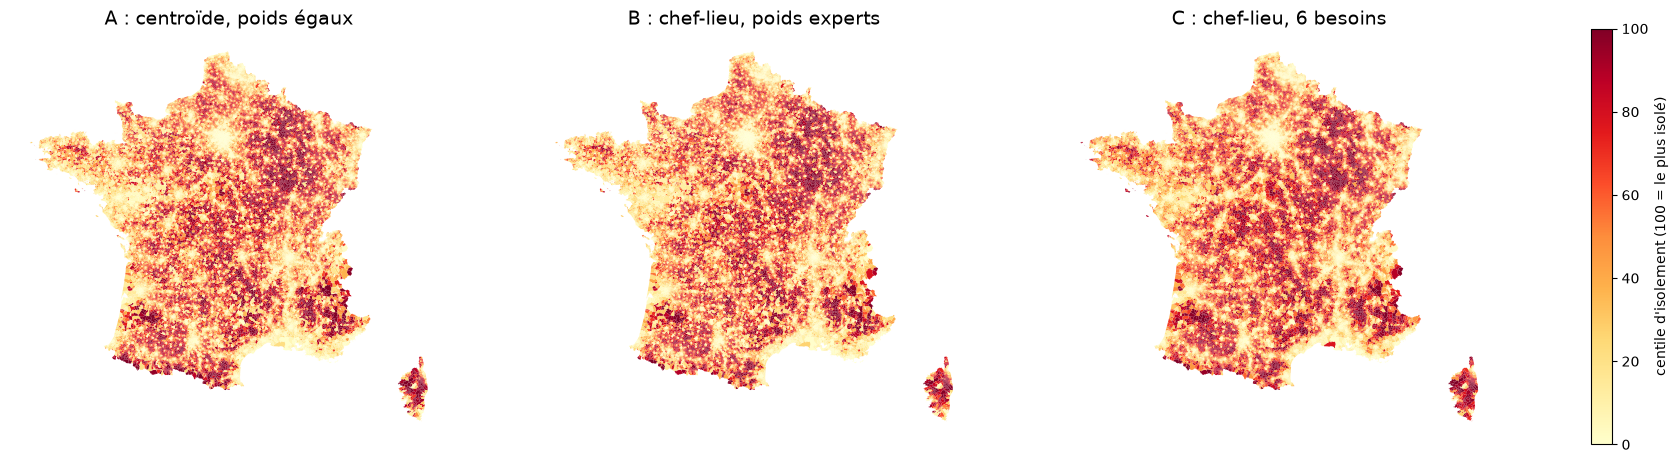

In [22]:
centile_A = (indice_A.rank(pct=True) * 100).rename("centile_A")
centile_B = (indice_B.rank(pct=True) * 100).rename("centile_B")
centile_C = (indice_C.rank(pct=True) * 100).rename("centile_C")
carte = geo.merge(pd.concat([centile_A, centile_B, centile_C], axis=1).rename_axis("code").reset_index(), on="code")

fig, axes = plt.subplots(1, 3, figsize=(24, 9))
for ax, col, titre in zip(axes, ["centile_A", "centile_B", "centile_C"],
                          ["A : centroïde, poids égaux", "B : chef-lieu, poids experts", "C : chef-lieu, 6 besoins"]):
    carte.plot(column=col, cmap="YlOrRd", vmin=0, vmax=100, linewidth=0, ax=ax)
    ax.set_axis_off()
    ax.set_title(titre, fontsize=14)
sm = plt.cm.ScalarMappable(cmap="YlOrRd", norm=plt.Normalize(0, 100))
fig.colorbar(sm, ax=axes, shrink=0.6, label="centile d'isolement (100 = le plus isolé)")
fig.savefig(FIGURES / "v5_cartes_A_B_C.png", dpi=150, bbox_inches="tight")
plt.show()

Les trois cartes dessinent les mêmes grandes zones d'isolement :
- la « diagonale » peu dense qui va des Ardennes et de la Champagne à la Bourgogne, puis au Massif central ;
- les massifs montagneux : Pyrénées, Alpes du Sud, Corse ;
- l'intérieur des Landes et du Sud-Ouest.

Les grandes agglomérations, la Bretagne, le littoral atlantique et la vallée du Rhône sont mieux desservis.

**A et B sont presque indiscernables à cette échelle.** Leur différence porte sur des communes isolées les unes des autres, surtout en montagne (partie 6).

**C se distingue nettement.** Les zones isolées y sont plus larges et plus lisses, et de **longs couloirs clairs** les traversent, en étoile depuis Paris : ce sont les lignes de chemin de fer. Le transport et l'hôpital pèsent chacun un sixième dans C, si bien que la proximité d'une gare et d'une ville hospitalière structure la carte.

### 5.2 Quel service manque, et où ?

L'indice résume 19 services, mais deux communes de même indice peuvent manquer de services différents. On cartographie la distance à six services (méthode B, `ln(1 + km)`), chacun avec sa propre échelle de couleurs, bornée au 98ᵉ centile.

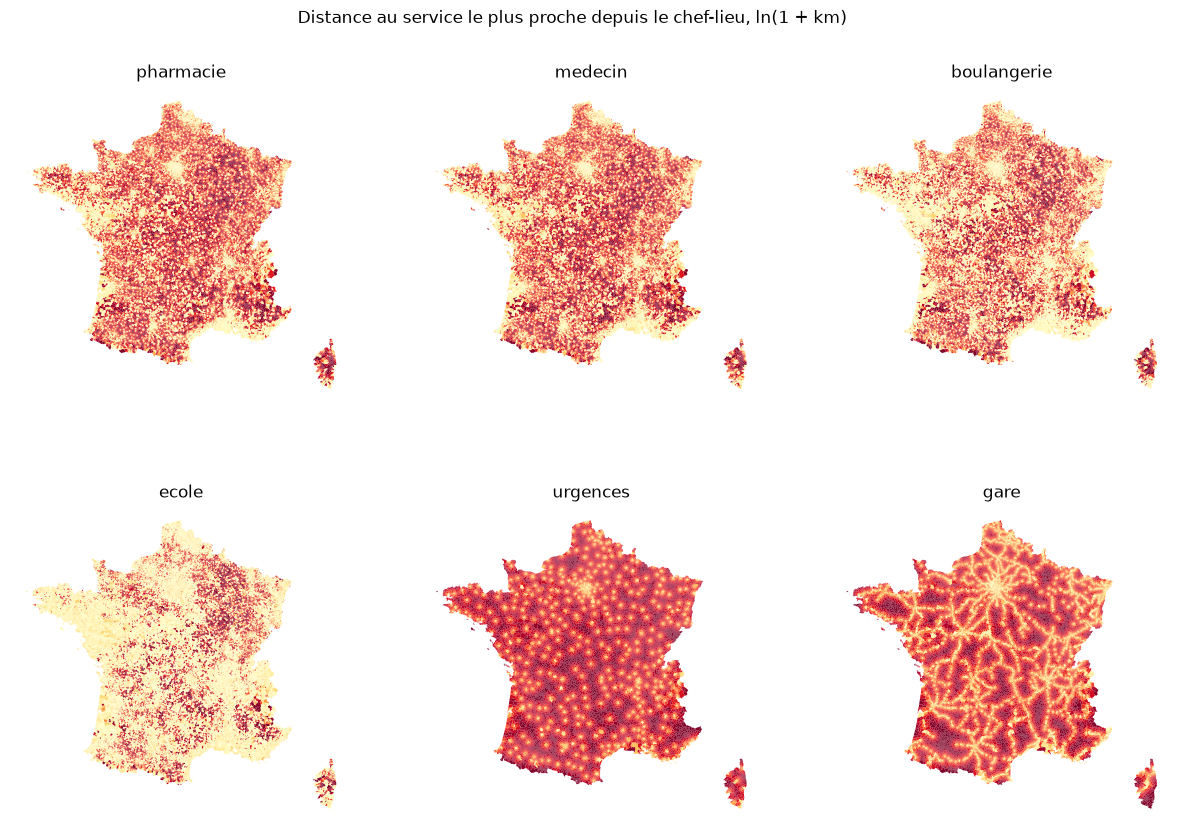

In [23]:
carte_services = geo.merge(dist_B.rename_axis("code").reset_index(), on="code")
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, service in zip(axes.ravel(), SERVICES_CARTES):
    valeurs = np.log1p(carte_services[service])
    carte_services.assign(valeur=valeurs).plot(column="valeur", cmap="YlOrRd", vmin=0,
                                               vmax=float(valeurs.quantile(0.98)), linewidth=0, ax=ax)
    ax.set_axis_off()
    ax.set_title(service)
fig.suptitle("Distance au service le plus proche depuis le chef-lieu, ln(1 + km)", y=0.94)
fig.savefig(FIGURES / "v5_cartes_services.png", dpi=150, bbox_inches="tight")
plt.show()

Les cartes par service ne se ressemblent pas. Pour la pharmacie, le médecin et la boulangerie, la plupart des communes sont proches, et seules la montagne et la diagonale peu dense ressortent. Pour l'école, presque tout le territoire est clair. Pour les urgences et la gare, c'est l'inverse : presque tout le territoire est foncé, seules les villes ressortent, et la carte des gares dessine même le réseau ferré. C'est pour cette raison qu'un indice a besoin de plusieurs services : un seul ne décrit pas l'isolement.

### 5.3 Isolement et densité (H2)

On mesure le lien avec la **corrélation de Spearman**, qui compare des classements plutôt que des valeurs : la densité est si asymétrique (de 0 à plus de 38 000 hab./km²) qu'une corrélation de Pearson serait dominée par quelques villes. ρ vaut −1 si les classements sont inversés, +1 s'ils sont identiques.

On range aussi les communes en 5 classes de densité de même effectif (quintiles) et on compare l'indice entre classes avec le **test de Kruskal-Wallis** et sa taille d'effet **ε²** (part de la variation des rangs expliquée par les classes, entre 0 et 1). Avec 35 000 communes, toutes les p-values sont minuscules : c'est la taille de l'effet qui compte.

,rho_spearman,epsilon2_KW,n
A,-0.843,0.680,34788.0
B,-0.826,0.654,34788.0
C,-0.840,0.678,34788.0


Indice médian par quintile de densité :


densite,1 (moins denses),2,3,4,5 (plus denses)
A,0.72,0.43,0.19,-0.16,-0.98
B,0.75,0.44,0.16,-0.20,-0.98
C,0.81,0.45,0.15,-0.24,-1.02


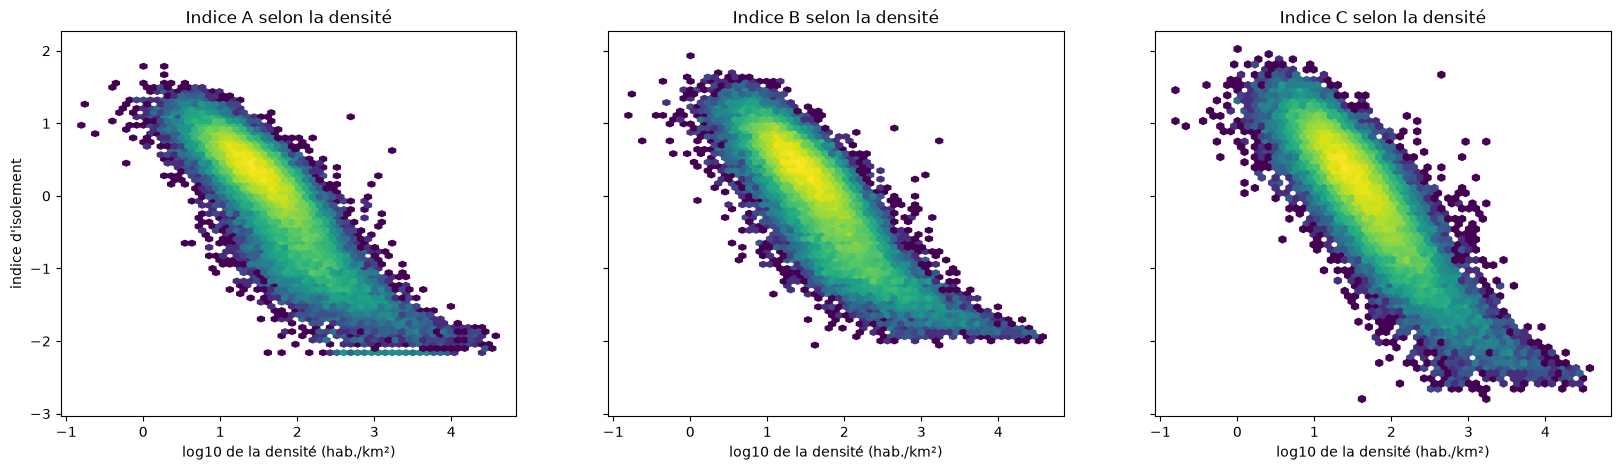

In [24]:
dens = base.set_index("code")["densite"]
NOMS_DENSITE = ["1 (moins denses)", "2", "3", "4", "5 (plus denses)"]
classe_densite = pd.qcut(dens.rank(method="first"), 5, labels=NOMS_DENSITE)

lignes, medianes = {}, {}
for nom, ind in [("A", indice_A), ("B", indice_B), ("C", indice_C)]:
    s = an.correlation_spearman(ind.reindex(dens.index), dens)
    kw, tab = an.comparer_groupes(ind.reindex(dens.index), classe_densite)
    lignes[nom] = {"rho_spearman": s["rho"], "epsilon2_KW": kw["epsilon2"], "n": s["n"]}
    medianes[nom] = ind.groupby(classe_densite, observed=True).median()
display(pd.DataFrame(lignes).T.round(3))
print("Indice médian par quintile de densité :")
display(pd.DataFrame(medianes).round(2).T)

fig, axes = plt.subplots(1, 3, figsize=(20, 5), sharey=True)
for ax, (nom, ind) in zip(axes, [("A", indice_A), ("B", indice_B), ("C", indice_C)]):
    ok = dens > 0
    ax.hexbin(np.log10(dens[ok]), ind.reindex(dens.index)[ok], gridsize=60, bins="log", cmap="viridis", mincnt=1)
    ax.set_xlabel("log10 de la densité (hab./km²)")
    ax.set_title(f"Indice {nom} selon la densité")
axes[0].set_ylabel("indice d'isolement")
fig.savefig(FIGURES / "v5_densite_A_B_C.png", dpi=150, bbox_inches="tight")
plt.show()

**H2 est confirmée, avec les trois méthodes.** Le lien entre densité et isolement est très fort : ρ = −0,84 avec A, −0,83 avec B et −0,84 avec C. La taille d'effet du test de Kruskal-Wallis est très élevée (ε² entre 0,65 et 0,68) : la classe de densité explique à elle seule environ deux tiers de la variation des rangs de l'indice. L'indice médian baisse régulièrement des communes les moins denses aux plus denses, avec les trois méthodes. L'écart est un peu plus grand avec C (de 0,81 à −1,02), qui sépare plus nettement les extrêmes.

C'est une corrélation, pas une preuve de causalité, mais le mécanisme est connu : un service s'installe là où il y a assez d'habitants pour le faire vivre.

### 5.4 Isolement et revenu (H3)

On ajoute le niveau de vie médian de chaque commune (Filosofi 2023, indicateur `MED_SL`). Le fichier est au format long (une ligne par territoire et par indicateur) : `an.lire_revenu` garde les communes (`COM`) et arrondissements (`ARM`) et l'indicateur `MED_SL`. Pour les petites communes, l'INSEE ne publie pas le revenu (secret statistique) : ces communes restent dans la base avec une case vide.

In [25]:
revenu = an.lire_revenu(RAW / "filosofi_2023.csv")
base_rev, journal_rev = an.fusionner_revenu(base, revenu)
revenu_s = base_rev.set_index("code")["revenu_median"]
print("Journal :", journal_rev)
print(f"Communes sans revenu publié : {revenu_s.isna().mean():.1%} "
      f"({pop[revenu_s.isna()].sum() / pop.sum():.2%} de la population)")
display(revenu_s.describe().round(0).to_frame("niveau de vie médian (€)").T)

# Les communes sans revenu sont-elles plus isolées ?
a_revenu = pd.Series(np.where(revenu_s.notna(), "avec revenu", "sans revenu"), index=revenu_s.index)
print("Indice médian selon que le revenu est publié ou non :")
display(pd.DataFrame({"A": indice_A.groupby(a_revenu).median(), "B": indice_B.groupby(a_revenu).median(),
                      "C": indice_C.groupby(a_revenu).median()}).round(2).T)

Journal : {'communes_base': 34788, 'communes_sans_revenu': 3976, 'codes_revenu_hors_base': 27}
Communes sans revenu publié : 11.4% (0.44% de la population)


,count,mean,std,min,25%,50%,75%,max
niveau de vie médian (€),30812.0,26270.0,3541.0,12420.0,24090.0,25780.0,27840.0,62730.0


Indice médian selon que le revenu est publié ou non :


,avec revenu,sans revenu
A,0.07,0.72
B,0.02,0.76
C,0.02,0.79


Le revenu médian est publié pour 30 812 communes. **Les 3 976 communes sans revenu (11,4 %) sont nettement plus isolées** que les autres, quelle que soit la méthode : indice médian de 0,72 à 0,79 selon la méthode, contre 0,02 à 0,07 pour les communes avec revenu. Elles ne regroupent pourtant que 0,44 % de la population : ce sont les plus petites communes, couvertes par le secret statistique. L'analyse du revenu porte donc sur un ensemble de communes moins isolé que l'ensemble, et **ne dit rien des communes les plus isolées**.

On mesure ensuite le lien entre l'indice et le revenu, puis on vérifie qu'il ne s'agit pas d'un simple effet de la densité. La densité est liée à l'isolement (5.3) **et** au revenu : elle peut créer un lien apparent entre les deux (facteur de confusion). On refait donc la corrélation **à l'intérieur** de chaque classe de densité, où la densité varie peu.

In [26]:
NOMS_REVENU = ["1 (plus modestes)", "2", "3", "4", "5 (plus aisées)"]
quintile_revenu = pd.qcut(revenu_s.rank(method="first"), 5, labels=NOMS_REVENU)
print(f"Spearman revenu / densité : {an.correlation_spearman(revenu_s, dens.reindex(revenu_s.index))['rho']:.3f}")

lignes, medianes, intra = {}, {}, {}
classe_d = classe_densite.reindex(revenu_s.index)
for nom, ind in [("A", indice_A), ("B", indice_B), ("C", indice_C)]:
    ind_r = ind.reindex(revenu_s.index)
    s = an.correlation_spearman(ind_r, revenu_s)
    kw, _ = an.comparer_groupes(ind_r, quintile_revenu)
    lignes[nom] = {"rho_spearman": s["rho"], "epsilon2_KW": kw["epsilon2"], "n": s["n"]}
    medianes[nom] = ind_r.groupby(quintile_revenu, observed=True).median()
    intra[nom] = {c: an.correlation_spearman(ind_r[classe_d == c], revenu_s[classe_d == c])["rho"] for c in NOMS_DENSITE}

display(pd.DataFrame(lignes).T.round(3))
print("Indice médian par quintile de revenu :")
display(pd.DataFrame(medianes).round(2).T)
print("Spearman indice / revenu à l'intérieur de chaque classe de densité :")
display(pd.DataFrame(intra).round(3).T)

Spearman revenu / densité : 0.347


,rho_spearman,epsilon2_KW,n
A,-0.216,0.050,30812.0
B,-0.210,0.048,30812.0
C,-0.306,0.095,30812.0


Indice médian par quintile de revenu :


revenu_median,1 (plus modestes),2,3,4,5 (plus aisées)
A,0.28,0.20,0.13,0.01,-0.23
B,0.25,0.18,0.10,-0.03,-0.29
C,0.34,0.21,0.08,-0.10,-0.40


Spearman indice / revenu à l'intérieur de chaque classe de densité :


,1 (moins denses),2,3,4,5 (plus denses)
A,-0.071,0.006,0.052,0.153,0.294
B,-0.060,0.013,0.053,0.145,0.280
C,-0.153,-0.116,-0.113,-0.043,0.165


**Avec A et B, H3 n'est que partiellement confirmée.** Globalement, les communes plus modestes sont un peu plus isolées (ρ = −0,22 et −0,21), mais l'effet est faible (ε² ≈ 0,05). Il vient surtout de la densité, liée à la fois au revenu (ρ = 0,35) et à l'isolement. À densité comparable, le lien disparaît (ρ proche de 0 dans les classes peu denses) puis devient positif dans les communes les plus denses (+0,28 à +0,29) : en ville, les communes aisées sont un peu plus loin des services, comme les couronnes résidentielles.

**Avec C, le lien est nettement plus fort et résiste en partie à la densité.**
- Globalement, ρ = −0,31 et ε² = 0,095, soit deux fois plus qu'avec A et B. L'indice médian passe de 0,34 dans le quintile le plus modeste à −0,40 dans le plus aisé.
- À densité comparable, ρ reste **négatif dans les quatre premières classes** (−0,15, −0,12, −0,11, −0,04). Il n'est positif que dans les communes les plus denses (+0,17).

C donne plus de poids à **la gare et à l'hôpital**. Le résultat suggère que c'est surtout l'éloignement de ces équipements rares, plus que celui des commerces ou des médecins, qui va de pair avec un revenu plus faible, même entre communes de densité semblable. Une explication possible, non vérifiée ici : les actifs plus aisés s'installent près des gares et des villes moyennes, où se concentrent aussi les emplois qualifiés.

Le diagnostic sur le revenu **dépend donc de la méthode** : faible et dû à la densité si l'on compte 19 services, plus marqué si l'on donne autant de poids à chaque grand besoin.

## Partie 6. Comparaison des méthodes

Les parties 2 à 5 donnent trois images de l'isolement. On compare d'abord en détail A et B, qui diffèrent par le point de départ, l'indicatrice et les poids (6.1 à 6.6), puis on situe C (6.7). On veut maintenant savoir **à quel point elles diffèrent**, **pour quelles communes**, et **lequel des deux choix** (point de départ ou poids) est responsable des différences.

### 6.1 Les deux classements se ressemblent-ils ?

La corrélation de Spearman entre A et B mesure la ressemblance des classements (1 = même ordre). On regarde aussi le tableau croisé des déciles : la part des communes qui restent dans le même dixième de la distribution, ou qui ne bougent que d'un décile.

Spearman A / B : 0.981
Même décile : 68.3% ; au plus un décile d'écart : 97.1% ; 3 déciles ou plus : 0.6%


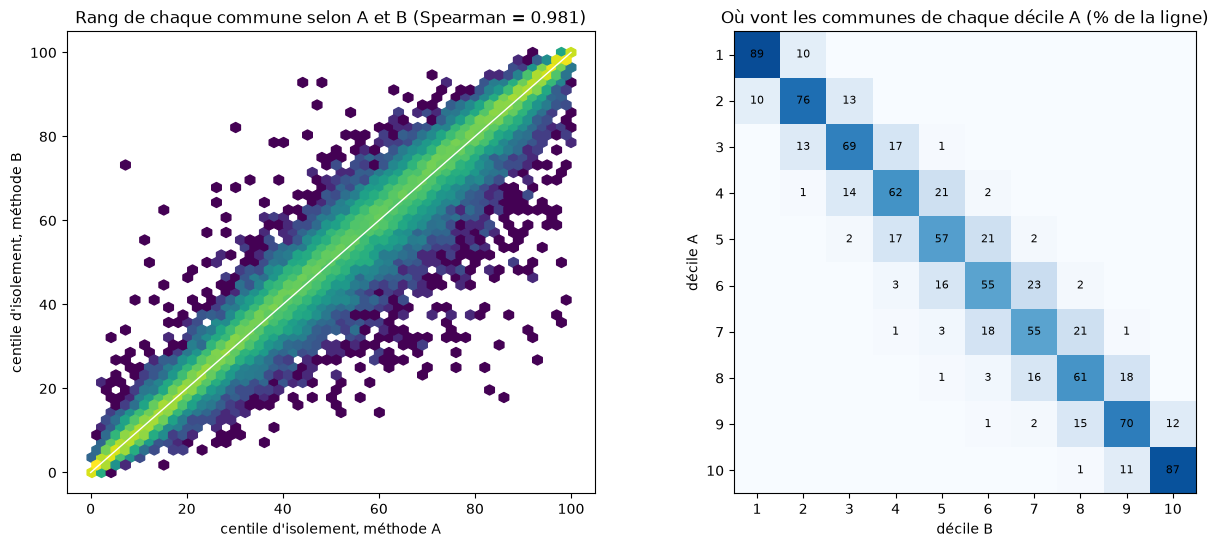

In [27]:
rho_AB = an.correlation_spearman(indice_A, indice_B)["rho"]
print(f"Spearman A / B : {rho_AB:.3f}")

decile_A = pd.qcut(indice_A.rank(method="first"), 10, labels=range(1, 11)).astype(int)
decile_B = pd.qcut(indice_B.rank(method="first"), 10, labels=range(1, 11)).astype(int)
saut = (decile_B - decile_A).abs()
print(f"Même décile : {(saut == 0).mean():.1%} ; au plus un décile d'écart : {(saut <= 1).mean():.1%} ; "
      f"3 déciles ou plus : {(saut >= 3).mean():.1%}")

croise = pd.crosstab(decile_A, decile_B, normalize="index").mul(100).round(0)
croise.index.name, croise.columns.name = "décile A", "décile B"

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].hexbin(centile_A, centile_B, gridsize=50, bins="log", cmap="viridis", mincnt=1)
axes[0].plot([0, 100], [0, 100], color="white", lw=1)
axes[0].set_xlabel("centile d'isolement, méthode A")
axes[0].set_ylabel("centile d'isolement, méthode B")
axes[0].set_title(f"Rang de chaque commune selon A et B (Spearman = {rho_AB:.3f})")
im = axes[1].imshow(croise.values, cmap="Blues", vmin=0, vmax=100)
axes[1].set_xticks(range(10)); axes[1].set_xticklabels(croise.columns)
axes[1].set_yticks(range(10)); axes[1].set_yticklabels(croise.index)
axes[1].set_xlabel("décile B"); axes[1].set_ylabel("décile A")
for i in range(10):
    for j in range(10):
        if croise.iloc[i, j] >= 1:
            axes[1].text(j, i, f"{croise.iloc[i, j]:.0f}", ha="center", va="center", fontsize=8)
axes[1].set_title("Où vont les communes de chaque décile A (% de la ligne)")
fig.savefig(FIGURES / "v5_comparaison_rangs.png", dpi=150, bbox_inches="tight")
plt.show()

**Les deux classements sont très proches : Spearman = 0,981.** Dans le tableau croisé, 68 % des communes restent dans le même décile, 97,1 % bougent d'au plus un décile, et 0,6 % (environ 200 communes) bougent de trois déciles ou plus.

Le nuage de points montre que les écarts ne sont pas répartis au hasard. Ils sont plus forts **au milieu de la distribution** qu'aux extrémités. Les communes très bien desservies (les villes, qui ont presque tout sur place) et les communes très isolées gardent leur place. Au milieu, de petites différences de distance suffisent à faire bouger le rang.

### 6.2 Qu'est-ce qui fait la différence : le point de départ, l'indicatrice ou les poids ?

A et B diffèrent sur trois choix à la fois. Pour séparer leurs effets, on calcule les $2 \times 2 \times 2 = 8$ indices qui combinent :
- le point de départ $x$ : centroïde ($x^A$) ou chef-lieu ($x^B$) ;
- la règle $r$ : avec indicatrice de présence ($r^A$) ou sans ($r^B$) ;
- les poids $w$ : égaux ($w^A$) ou experts ($w^B$).

On note $I_c^{(x,\,r,\,w)}$ l'indice correspondant, de sorte que $A = I^{(x^A,\,r^A,\,w^A)}$ et $B = I^{(x^B,\,r^B,\,w^B)}$. On mesure l'écart de classement entre deux indices par $1 - \rho_S$, où $\rho_S$ est la corrélation de Spearman (0 = même classement). En partant de A et en ne changeant qu'un ingrédient à la fois, on voit lequel déplace le plus le classement.

Spearman de chacun des 8 indices avec A :


poids                    egaux  experts
centre    règle                        
centroide presence       1.000    0.998
          sans_presence  0.963    0.963
chef_lieu presence       0.987    0.985
          sans_presence  0.982    0.981

,1 - Spearman avec A (0 = aucun changement de classement)
poids seulement,0.0025
indicatrice seulement (centroïde sans présence),0.0366
centre seulement (chef-lieu avec présence),0.0125
centre + indicatrice,0.0176
les trois (A → B),0.0194


Effet d'enlever l'indicatrice (poids égaux), 1 - Spearman :
  depuis le centroïde : 0.0366
  depuis le chef-lieu : 0.0037


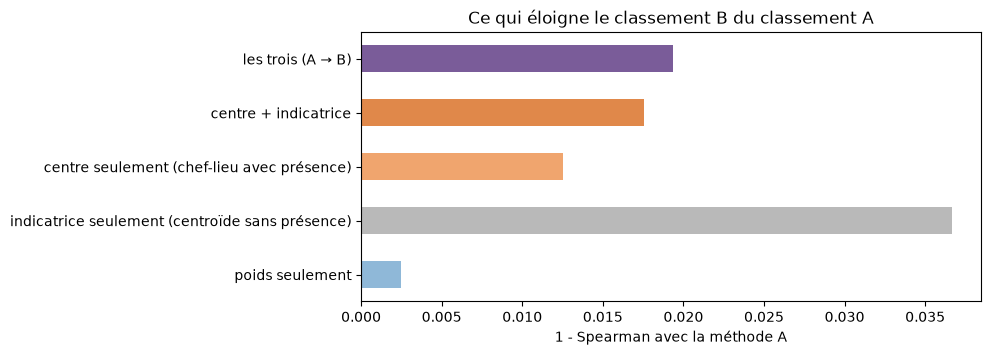

In [28]:
# Les 4 tables de distances (point de départ x règle de présence)
distances_cr = {
    ("centroide", "presence"): dist_A,
    ("centroide", "sans_presence"): dist.distances_par_service(base_A, equipements, services, regle_presence=False)[0],
    ("chef_lieu", "presence"): dist.distances_par_service(base_B, equipements, services)[0],
    ("chef_lieu", "sans_presence"): dist_B,
}
huit = {}
for (nom_c, nom_r), d in distances_cr.items():
    z = idx.standardiser(idx.log_distance(d))
    for nom_p, p in [("egaux", poids_A), ("experts", poids_B)]:
        huit[(nom_c, nom_r, nom_p)] = idx.indice_pondere(z, p)
huit = pd.DataFrame(huit)
huit.columns.names = ["centre", "règle", "poids"]
assert np.allclose(huit[("centroide", "presence", "egaux")], indice_A)
assert np.allclose(huit[("chef_lieu", "sans_presence", "experts")], indice_B)

rho_huit = huit.rank().corrwith(indice_A.rank())
print("Spearman de chacun des 8 indices avec A :")
display(rho_huit.round(3).unstack("poids"))

effets = pd.Series({
    "poids seulement": 1 - rho_huit[("centroide", "presence", "experts")],
    "indicatrice seulement (centroïde sans présence)": 1 - rho_huit[("centroide", "sans_presence", "egaux")],
    "centre seulement (chef-lieu avec présence)": 1 - rho_huit[("chef_lieu", "presence", "egaux")],
    "centre + indicatrice": 1 - rho_huit[("chef_lieu", "sans_presence", "egaux")],
    "les trois (A → B)": 1 - rho_huit[("chef_lieu", "sans_presence", "experts")],
}).rename("1 - Spearman avec A (0 = aucun changement de classement)")
display(effets.round(4).to_frame())

# L'effet de l'indicatrice dépend-il du point de départ ?
r = huit.rank()
print("Effet d'enlever l'indicatrice (poids égaux), 1 - Spearman :")
print(f"  depuis le centroïde : {1 - r[('centroide', 'presence', 'egaux')].corr(r[('centroide', 'sans_presence', 'egaux')]):.4f}")
print(f"  depuis le chef-lieu : {1 - r[('chef_lieu', 'presence', 'egaux')].corr(r[('chef_lieu', 'sans_presence', 'egaux')]):.4f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
effets.plot.barh(ax=ax, color=["#8FB8D8", "#B9B9B9", "#F0A56E", "#E0884A", "#7A5C99"])
ax.set_xlabel("1 - Spearman avec la méthode A")
ax.set_title("Ce qui éloigne le classement B du classement A")
fig.savefig(FIGURES / "v5_decomposition.png", dpi=150, bbox_inches="tight")
plt.show()

**Pris isolément, enlever l'indicatrice depuis le centroïde est le changement le plus perturbateur, mais il ne l'est plus depuis le chef-lieu.** En partant de A et en ne changeant qu'un ingrédient (1 − ρ avec A) :
- changer les poids : 0,0025, le classement ne bouge presque pas ;
- changer le point de départ : 0,0125, soit cinq fois plus que les poids ;
- enlever l'indicatrice depuis le centroïde : 0,0366, l'effet le plus fort.

Mais l'effet de l'indicatrice **dépend du point de départ**. L'enlever coûte 0,0366 depuis le centroïde, et seulement 0,0037 depuis le chef-lieu, soit dix fois moins. Depuis le centroïde, point arbitraire, la distance réelle à l'équipement de la commune est un artefact de la forme du territoire, d'où l'utilité de l'indicatrice. Depuis la mairie, cette distance est faible et a un sens (voir 3.3), si bien que l'indicatrice n'apporte presque rien. **C'est ce qui justifie de l'enlever dans la méthode B.**

Au total, A → B donne 0,0194 (ρ = 0,981), dont l'essentiel vient du changement de point de départ. Les poids comptent peu pour deux raisons. La grille experte redistribue surtout le poids **à l'intérieur** des thèmes (3.1). Et les 19 distances varient ensemble (la première composante de l'ACP en résume 51 %) : toute pondération à poids positifs classe les communes dans un ordre voisin.

### 6.3 Les communes les plus isolées sont-elles les mêmes ?

Pour l'action publique, ce qui compte souvent est la liste des communes **les plus** isolées (pour cibler une aide, par exemple). On compare les 10 % de communes les plus isolées selon A et selon B : combien sont communes aux deux listes, et combien d'habitants chacune représente.

In [29]:
top_A = set(indice_A[indice_A >= indice_A.quantile(0.9)].index)
top_B = set(indice_B[indice_B >= indice_B.quantile(0.9)].index)
commun = top_A & top_B
print(f"10 % les plus isolées : {len(top_A):,} communes selon A, {len(top_B):,} selon B, {len(commun):,} en commun "
      f"({len(commun) / len(top_A):.1%} de recouvrement)")
print(f"Population couverte : A = {pop[list(top_A)].sum():,.0f} hab. ; B = {pop[list(top_B)].sum():,.0f} hab. ; "
      f"les deux = {pop[list(commun)].sum():,.0f} hab.")

recouvrement = {}
for q in [0.99, 0.95, 0.9, 0.75, 0.5]:
    ta = set(indice_A[indice_A >= indice_A.quantile(q)].index)
    tb = set(indice_B[indice_B >= indice_B.quantile(q)].index)
    recouvrement[f"{100 - q * 100:.0f} % les plus isolées"] = len(ta & tb) / len(ta) * 100
display(pd.Series(recouvrement).round(1).to_frame("communes présentes dans les deux listes (%)").T)

10 % les plus isolées : 3,479 communes selon A, 3,479 selon B, 3,044 en commun (87.5% de recouvrement)
Population couverte : A = 486,434 hab. ; B = 491,710 hab. ; les deux = 407,668 hab.


,1 % les plus isolées,5 % les plus isolées,10 % les plus isolées,25 % les plus isolées,50 % les plus isolées
communes présentes dans les deux listes (%),80.2,83.9,87.5,90.7,94.9


Pour cibler les communes à aider, le choix de méthode compte un peu plus que ne le laisse penser la corrélation globale. **Sur les 3 479 communes les plus isolées (10 %), 3 044 sont les mêmes avec A et B (87,5 %)**, et 435 changent. Plus la liste est courte, plus le désaccord est grand : le recouvrement est de 84 % pour les 5 % les plus isolées et de **80 % pour le 1 %** le plus isolé. Une politique qui viserait les 350 communes les plus isolées en désignerait donc environ 70 différentes selon la méthode. Ces listes couvrent un peu moins de 500 000 habitants.

### 6.4 Quelles communes changent de rang, et pourquoi ?

On calcule pour chaque commune le changement de centile entre A et B (positif = plus isolée selon B). On regarde si les grands changements s'expliquent par l'écart entre centroïde et chef-lieu, par la surface ou par la population, et on liste les communes qui bougent le plus dans chaque sens.

In [30]:
mouvement = (centile_B - centile_A).rename("centile_B - centile_A")
cadre_mvt = base_B.set_index("code")[["nom", "population", "surface_km2", "ecart_centre_km"]].join(
    [centile_A.round(1), centile_B.round(1), mouvement.round(1)])

liens = pd.Series({
    "écart centroïde - chef-lieu": an.correlation_spearman(mouvement.abs(), ecart)["rho"],
    "surface": an.correlation_spearman(mouvement.abs(), surface)["rho"],
    "population": an.correlation_spearman(mouvement.abs(), pop)["rho"],
}).rename("Spearman avec |changement de centile|")
display(liens.round(3).to_frame())

classes_ecart = pd.cut(ecart, [-0.01, 0.5, 1, 2, 5, np.inf], labels=["< 0,5 km", "0,5-1 km", "1-2 km", "2-5 km", "> 5 km"])
display(pd.DataFrame({
    "communes": classes_ecart.value_counts().sort_index(),
    "changement_absolu_median": mouvement.abs().groupby(classes_ecart, observed=True).median().round(1),
    "changement_moyen_signé": mouvement.groupby(classes_ecart, observed=True).mean().round(1),
}).T)

print("Communes qui deviennent nettement PLUS isolées avec B :")
display(cadre_mvt.sort_values("centile_B - centile_A", ascending=False).head(8))
print("Communes qui deviennent nettement MOINS isolées avec B :")
display(cadre_mvt.sort_values("centile_B - centile_A").head(8))

,Spearman avec |changement de centile|
écart centroïde - chef-lieu,0.227
surface,0.040
population,-0.102


ecart_centre_km,"< 0,5 km","0,5-1 km",1-2 km,2-5 km,> 5 km
communes,10218.0,12722.0,9404.0,2319.0,125.0
changement_absolu_median,1.8,2.3,3.0,4.1,7.0
changement_moyen_signé,1.3,0.6,-1.0,-4.4,-11.0


Communes qui deviennent nettement PLUS isolées avec B :


,nom,population,surface_km2,ecart_centre_km,centile_A,centile_B,centile_B - centile_A
code,,,,,,,
2B251,Prunelli-di-Fiumorbo,3880,37.712969,3.511273,7.5,72.8,65.3
2A228,Pietrosella,2074,35.669089,2.830252,29.8,82.8,53.0
28330,Villemaury,1283,77.301027,1.449171,43.3,92.8,49.4
2A209,Peri,2044,24.124535,0.686778,15.8,62.7,46.9
19124,Mansac,1554,18.773029,1.062094,10.5,56.0,45.4
2B079,Castello-di-Rostino,522,12.513648,1.662414,48.2,92.7,44.4
73290,Val-Cenis,2112,455.423629,4.126103,37.4,78.3,40.9
12043,Calmont,2192,30.805780,1.448275,26.9,67.1,40.3


Communes qui deviennent nettement MOINS isolées avec B :


,nom,population,surface_km2,ecart_centre_km,centile_A,centile_B,centile_B - centile_A
code,,,,,,,
48105,Naussac-Fontanes,372,25.034217,5.801048,86.9,17.8,-69.1
48089,Le Malzieu-Forain,484,49.492961,4.785535,93.1,25.8,-67.2
06013,Belvédère,601,75.341333,6.286396,82.3,19.8,-62.5
09023,Ascou,113,35.757276,5.689503,97.1,35.8,-61.2
65465,Vielle-Aure,315,35.430557,10.164547,92.2,32.1,-60.1
64354,Louvie-Soubiron,133,26.479194,6.891400,97.2,38.0,-59.2
09024,Aston,197,154.244501,10.442515,99.0,41.5,-57.4
64433,Osse-en-Aspe,330,43.206604,4.701457,82.3,25.8,-56.5


**Les communes dont le centroïde est loin du chef-lieu deviennent moins isolées avec B.** Quand l'écart entre les deux points dépasse 5 km, le centile baisse de 11 points en moyenne (−4,4 entre 2 et 5 km). Quand l'écart est faible, il monte légèrement (+1,3 sous 0,5 km). Comme on compare des rangs, les communes qui reculent font mécaniquement monter les autres. L'ampleur du changement est d'abord liée à l'écart entre les deux centres (Spearman de 0,23).

**Les plus fortes baisses (−56 à −69 centiles)** sont des communes de montagne dont le bourg est dans une vallée équipée et le centroïde en altitude : Vielle-Aure (Hautes-Pyrénées), Aston et Ascou (Ariège), Louvie-Soubiron et Osse-en-Aspe (Pyrénées-Atlantiques), Belvédère (Alpes-Maritimes). On y trouve aussi des communes de Lozère dont le chef-lieu touche un bourg équipé voisin : Naussac-Fontanes à côté de Langogne, Le Malzieu-Forain à côté du Malzieu-Ville. Selon A, elles faisaient partie des 20 % les plus isolées. Selon B, elles sont dans la moitié la moins isolée.

**Les plus fortes hausses (+40 à +65 centiles)** révèlent la limite de B : la mairie n'est pas toujours là où vivent les habitants.
- **En Corse**, Prunelli-di-Fiumorbo, Pietrosella, Peri et Castello-di-Rostino ont gardé leur mairie dans le village perché historique, alors que la population et les commerces sont descendus vers la plaine ou la côte (Migliacciaro pour Prunelli-di-Fiumorbo). Sans l'indicatrice, les services de la commune comptent pour leur distance réelle à la mairie, qui est grande.
- **Les communes nouvelles**, nées de la fusion de plusieurs communes, comme Val-Cenis (Savoie) ou Villemaury (Eure-et-Loir), n'ont qu'un chef-lieu, alors que leurs services sont répartis entre les anciens villages.

Ces communes de 500 à 3 900 habitants passent du milieu au haut du classement. Pour elles, A (qui met les services présents à 0) est sans doute plus juste que B.

### 6.5 Robustesse élargie : au-delà de A et B

A et B ne sont que deux combinaisons parmi beaucoup d'autres possibles. On croise :
- 2 points de départ (centroïde, chef-lieu) ;
- 3 règles de distance : `presence` (référence : 0 si le service est dans la commune), `sans_presence` (on prend toujours la distance au plus proche équipement, même dans la commune), `positions_AB` (seuls les équipements dont la position est de qualité A ou B, les plus fiables selon l'INSEE, servent aux distances) ;
- 5 jeux de poids : égaux, experts, « vitaux » (urgences, maternité, médecin, pharmacie et santé de proximité comptent double), « thèmes » (chaque thème pèse autant : la santé ne domine plus), et ACP (première composante principale des `z`, c'est-à-dire les poids que suggèrent les données elles-mêmes).

Cela fait 2 × 3 × 5 = 30 indices, que l'on compare à A (centroïde, `presence`, égaux) et à B (chef-lieu, `sans_presence`, experts).

In [31]:
jeux_poids = {"egaux": idx.poids_egaux(services), "experts": idx.poids_experts(services),
              "vitaux": idx.poids_vitaux(services), "themes": idx.poids_themes_equilibres(services)}
regles = {"presence": {}, "sans_presence": {"regle_presence": False}, "positions_AB": {"qualites": QUALITES_FIABLES}}
centres = {"centroide": base_A, "chef_lieu": base_B}

grille_indices = pd.DataFrame(index=indice_A.index)
part_pc1 = {}
for nom_c, base_c in centres.items():
    for nom_r, options in regles.items():
        d = distances_cr[(nom_c, nom_r)] if (nom_c, nom_r) in distances_cr else             dist.distances_par_service(base_c, equipements, services, **options)[0]
        z = idx.standardiser(idx.log_distance(d))
        for nom_p, p in jeux_poids.items():
            grille_indices[(nom_c, nom_r, nom_p)] = idx.indice_pondere(z, p)
        grille_indices[(nom_c, nom_r, "acp")], part_pc1[(nom_c, nom_r)] = idx.indice_acp(z, grille_indices[(nom_c, nom_r, "egaux")])
grille_indices.columns = pd.MultiIndex.from_tuples(grille_indices.columns, names=["centre", "règle", "poids"])

assert np.allclose(grille_indices[("centroide", "presence", "egaux")], indice_A)
assert np.allclose(grille_indices[("chef_lieu", "sans_presence", "experts")], indice_B)
print("Part de variance expliquée par la 1re composante de l'ACP :", {k: round(v, 3) for k, v in part_pc1.items()})

rangs = grille_indices.rank()
rho_vs_A = rangs.corrwith(indice_A.rank())
rho_vs_B = rangs.corrwith(indice_B.rank())
ordre_poids = ["egaux", "experts", "vitaux", "themes", "acp"]
print("Spearman de chaque indice avec la méthode A :")
display(rho_vs_A.unstack("poids")[ordre_poids].round(3))
print("Spearman de chaque indice avec la méthode B :")
display(rho_vs_B.unstack("poids")[ordre_poids].round(3))
toutes = rangs.corr()
print(f"Corrélation la plus faible entre deux des 30 indices : {toutes.values.min():.3f}")

Part de variance expliquée par la 1re composante de l'ACP : {('centroide', 'presence'): 0.516, ('centroide', 'sans_presence'): 0.541, ('centroide', 'positions_AB'): 0.514, ('chef_lieu', 'presence'): 0.519, ('chef_lieu', 'sans_presence'): 0.511, ('chef_lieu', 'positions_AB'): 0.516}
Spearman de chaque indice avec la méthode A :


poids                    egaux  experts  vitaux  themes    acp
centre    règle                                               
centroide positions_AB   0.996    0.995   0.991   0.976  0.996
          presence       1.000    0.998   0.996   0.979  0.999
          sans_presence  0.963    0.963   0.960   0.940  0.964
chef_lieu positions_AB   0.985    0.983   0.981   0.966  0.984
          presence       0.987    0.985   0.984   0.968  0.986
          sans_presence  0.982    0.981   0.979   0.963  0.981

Spearman de chaque indice avec la méthode B :


poids                    egaux  experts  vitaux  themes    acp
centre    règle                                               
centroide positions_AB   0.976    0.978   0.972   0.957  0.977
          presence       0.981    0.982   0.977   0.960  0.981
          sans_presence  0.945    0.948   0.942   0.922  0.947
chef_lieu positions_AB   0.991    0.992   0.987   0.971  0.991
          presence       0.995    0.996   0.992   0.974  0.995
          sans_presence  0.998    1.000   0.993   0.977  0.998

Corrélation la plus faible entre deux des 30 indices : 0.916


Les 30 indices restent tous très corrélés : **la plus faible corrélation entre deux d'entre eux est de 0,92**, au-dessus du seuil usuel de 0,9 pour des classements « très proches ». Quatre enseignements :

1. **Les jeux de poids comptent peu**, sauf le jeu « thèmes », qui donne à la gare seule le poids de tout un thème (20 %). C'est le jeu le plus éloigné : 0,98 avec A sur la même ligne, 0,98 avec B. Les poids de l'ACP sont presque des poids égaux (0,999 avec A) : la première composante explique 51 à 54 % de la variance dans les six configurations.
2. **Avec le chef-lieu, garder ou enlever l'indicatrice ne change presque rien** : 0,996 avec B pour la variante `presence`. Avec le centroïde, enlever l'indicatrice change nettement le classement : 0,963 avec A. La méthode B est donc peu sensible à ce choix, ce qui n'est pas le cas d'un indice construit sur le centroïde.
3. **Les positions de moindre qualité (M, U) ne faussent pas le résultat** : ne garder que les positions A et B donne 0,996 avec A (centroïde) et 0,992 avec B (chef-lieu).
4. **Le point de départ reste le choix qui sépare le plus les familles d'indices** : tous les indices calculés depuis le centroïde sont à 0,92 à 0,98 de B, tous ceux calculés depuis le chef-lieu à 0,97 à 1,00.

### 6.6 Les conclusions changent-elles avec la méthode ?

Dernière question, la plus importante : nos conclusions sur la densité (H2) et le revenu (H3) tiennent-elles quel que soit l'indice ? On recalcule les deux corrélations pour les 30 indices et on résume leur étendue.

In [32]:
conclusions = pd.DataFrame({
    "rho_densite": {c: an.correlation_spearman(grille_indices[c].reindex(dens.index), dens)["rho"] for c in grille_indices.columns},
    "rho_revenu": {c: an.correlation_spearman(grille_indices[c].reindex(revenu_s.index), revenu_s)["rho"] for c in grille_indices.columns},
})
conclusions.index = pd.MultiIndex.from_tuples(conclusions.index, names=["centre", "règle", "poids"])
display(conclusions.describe().loc[["min", "50%", "max"]].round(3))
print("Valeurs pour A et B :")
display(conclusions.loc[[("centroide", "presence", "egaux"), ("chef_lieu", "sans_presence", "experts")]].round(3))

,rho_densite,rho_revenu
min,-0.861,-0.287
50%,-0.834,-0.222
max,-0.822,-0.197


Valeurs pour A et B :


,,,rho_densite,rho_revenu
centre,règle,poids,,
centroide,presence,egaux,-0.843,-0.216
chef_lieu,sans_presence,experts,-0.826,-0.210


**Pour la densité, la conclusion ne dépend pas de la méthode.** Sur les 30 variantes de A et B, la corrélation avec la densité reste comprise entre −0,82 et −0,86. C est dans cet intervalle (−0,84).

**Pour le revenu, elle dépend de l'agrégation.** Sur les 30 variantes, la corrélation avec le revenu va de −0,20 à −0,29 : faible et négative partout. A (−0,22) et B (−0,21) sont dans cet intervalle. **C en sort, à −0,31.** Aucune variante de point de départ, d'indicatrice ou de poids par service ne donne un lien aussi fort que le regroupement en besoins (voir 5.4 et 6.7).

### 6.7 Et la méthode C ?

C reprend les distances de B et ne change que l'agrégation : 6 besoins à poids égaux au lieu de 19 services pondérés. On mesure à quel point cela change le classement, quelles communes sont concernées, et pourquoi.

In [33]:
trois = pd.concat([indice_A, indice_B, indice_C], axis=1)
display(trois.corr(method="spearman").round(3))

recouv = {}
for (n1, i1), (n2, i2) in [(("A", indice_A), ("B", indice_B)), (("B", indice_B), ("C", indice_C)), (("A", indice_A), ("C", indice_C))]:
    for q in [0.99, 0.9]:
        t1 = set(i1[i1 >= i1.quantile(q)].index)
        t2 = set(i2[i2 >= i2.quantile(q)].index)
        recouv.setdefault(f"{n1} / {n2}", {})[f"{100 - q * 100:.0f} % les plus isolées"] = len(t1 & t2) / len(t1) * 100
print("Communes présentes dans les deux listes (%) :")
display(pd.DataFrame(recouv).T.round(1))

# Qui bouge entre B et C, et à cause de quel besoin ?
mouvement_BC = (centile_C - centile_B).rename("centile_C - centile_B")
cadre_BC = base.set_index("code")[["nom", "population"]].join([centile_B.round(1), centile_C.round(1), mouvement_BC.round(1)])
cadre_BC["besoin le plus éloigné"] = besoin_max
print(f"Changement absolu médian de centile entre B et C : {mouvement_BC.abs().median():.1f} "
      f"(entre A et B : {(centile_B - centile_A).abs().median():.1f})")
print("Communes qui deviennent nettement PLUS isolées avec C :")
display(cadre_BC.sort_values("centile_C - centile_B", ascending=False).head(8))
print("Communes qui deviennent nettement MOINS isolées avec C :")
display(cadre_BC.sort_values("centile_C - centile_B").head(8))

# Quel besoin explique le déplacement ? Corrélation de chaque z de besoin avec le mouvement
print("Spearman entre le z de chaque besoin et le changement de centile B → C :")
display(pd.Series({noms_besoins[g]: an.correlation_spearman(z_C[g], mouvement_BC)["rho"] for g in z_C.columns})
        .sort_values().round(3).to_frame("rho"))

,A,B,C
A,1.000,0.981,0.946
B,0.981,1.000,0.954
C,0.946,0.954,1.000


Communes présentes dans les deux listes (%) :


,1 % les plus isolées,10 % les plus isolées
A / B,80.2,87.5
B / C,71.6,78.4
A / C,69.3,78.2


Changement absolu médian de centile entre B et C : 4.8 (entre A et B : 2.3)
Communes qui deviennent nettement PLUS isolées avec C :


,nom,population,centile_B,centile_C,centile_C - centile_B,besoin le plus éloigné
code,,,,,,
85113,L'Île-d'Yeu,4883,29.2,89.3,60.1,Démarches et accompagnement social
2A041,Bonifacio,3344,18.8,72.5,53.7,Se déplacer
36123,Mézières-en-Brenne,941,25.5,78.0,52.5,Scolariser ses enfants
29155,Ouessant,860,38.4,89.9,51.5,Scolariser ses enfants
63283,Pontaumur,670,20.7,72.0,51.3,Se déplacer
73304,Val-d'Isère,1567,34.5,85.2,50.7,Démarches et accompagnement social
13096,Saintes-Maries-de-la-Mer,2433,27.2,77.8,50.6,Scolariser ses enfants
48096,Meyrueis,770,20.0,70.3,50.2,Se déplacer


Communes qui deviennent nettement MOINS isolées avec C :


,nom,population,centile_B,centile_C,centile_C - centile_B,besoin le plus éloigné
code,,,,,,
09327,Ventenac,234,89.0,59.2,-29.9,Se soigner au quotidien
09044,Baulou,164,70.6,40.8,-29.8,Démarches et accompagnement social
41118,Loreux,238,83.0,53.4,-29.6,Faire ses courses
25515,Sainte-Colombe,488,62.0,32.6,-29.5,Faire ses courses
58025,Béard,160,86.2,56.9,-29.3,Se soigner au quotidien
03152,Louroux-de-Bouble,226,76.8,47.7,-29.1,Soins hospitaliers
88242,Houéville,43,77.0,48.3,-28.8,Se soigner au quotidien
02799,Vierzy,384,74.9,46.4,-28.5,Faire ses courses


Spearman entre le z de chaque besoin et le changement de centile B → C :


,rho
Se soigner au quotidien,-0.160
Faire ses courses,-0.141
Démarches et accompagnement social,-0.002
Scolariser ses enfants,0.204
Soins hospitaliers,0.375
Se déplacer,0.503


**C est la méthode qui s'écarte le plus des deux autres.** Sa corrélation de rangs est de 0,954 avec B et 0,946 avec A, contre 0,981 entre A et B. Le changement de centile médian entre B et C est de 4,8 points, deux fois plus qu'entre A et B (2,3). Les listes de communes les plus isolées divergent aussi davantage : seulement **78 % de recouvrement** entre B et C sur les 10 % les plus isolées (contre 87,5 % entre A et B), et **72 % sur le 1 %**. Changer **l'agrégation** pèse donc plus que changer le point de départ ou les poids service par service.

**Ce qui fait bouger les communes, c'est le transport et l'hôpital.** Le changement de centile entre B et C est d'abord lié à l'éloignement de la gare (ρ = 0,50), puis à celui de l'hôpital (0,38) et de l'école (0,20). Il est en revanche lié négativement aux soins courants (−0,16) et aux courses (−0,14). Les communes loin d'une gare ou d'un hôpital reculent avec C, celles qui manquent surtout de commerces ou de médecins avancent.

**Les plus fortes hausses (+50 à +60 centiles)** sont des communes **bien équipées sur place mais loin des grands réseaux** :
- les îles : L'Île-d'Yeu, Ouessant ;
- les bouts de territoire : Bonifacio, Saintes-Maries-de-la-Mer en Camargue, Val-d'Isère en fond de vallée ;
- les petits bourgs-centres ruraux : Mézières-en-Brenne, Pontaumur, Meyrueis.

Avec 19 services, leurs commerces, médecins et écoles les classaient dans la moitié la mieux desservie. Avec 6 besoins, la distance à la gare, au lycée et à l'hôpital les fait passer dans le tiers le plus isolé. Pour une île ou un fond de vallée, c'est plutôt une correction juste.

**Les plus fortes baisses (environ −30 centiles)** sont de petits villages (Ventenac, Baulou, Loreux, Béard…) dont le plus grand retard porte sur **les soins courants, les courses ou les démarches**, c'est-à-dire des services de proximité. Ils sont probablement moins loin d'une gare ou d'un hôpital que la moyenne. C les juge moins isolés que B, car le manque de services de proximité y pèse moins.

## Table finale

On enregistre une ligne par commune avec les trois indices, leurs centiles, le besoin le plus éloigné (C), la distance moyenne pondérée en km (B), la population, la densité et le revenu, dans `data/processed/communes_analyse_v5.parquet`.

In [34]:
final = base_B.set_index("code")[["nom", "population", "surface_km2", "densite", "ecart_centre_km"]].copy()
final["revenu_median"] = revenu_s
final["indice_A"] = indice_A
final["indice_B"] = indice_B
final["centile_A"] = centile_A.round(1)
final["indice_C"] = indice_C
final["centile_B"] = centile_B.round(1)
final["centile_C"] = centile_C.round(1)
final["km_pondere_B"] = km_B.round(2)
final["besoin_le_plus_eloigne"] = besoin_max

final.reset_index().to_parquet(PROCESSED / "communes_analyse_v5.parquet", index=False)
dist_A.reset_index().to_parquet(PROCESSED / "distances_A.parquet", index=False)
dist_B.reset_index().to_parquet(PROCESSED / "distances_B.parquet", index=False)
print(f"Enregistré : {final.shape[0]:,} communes, {final.shape[1]} colonnes")
display(final.sort_values("indice_B", ascending=False).head(10))

Enregistré : 34,788 communes, 14 colonnes


,nom,population,surface_km2,densite,ecart_centre_km,revenu_median,indice_A,indice_B,centile_A,indice_C,centile_B,centile_C,km_pondere_B,besoin_le_plus_eloigne
code,,,,,,,,,,,,,,
2B153,Manso,116,121.254632,0.956664,2.067211,NaN,1.762382,1.930587,100.0,2.023961,100.0,100.0,17.89,Scolariser ses enfants
51371,Moivre,54,22.175960,2.435069,2.185429,NaN,1.526823,1.694517,100.0,1.713092,100.0,99.9,14.58,Faire ses courses
21237,Échalot,93,27.665546,3.361582,0.555236,NaN,1.535967,1.692516,100.0,1.877109,100.0,100.0,15.85,Scolariser ses enfants
43054,Chanaleilles,173,48.545553,3.563663,0.455147,23380.0,1.497982,1.675507,100.0,1.736679,100.0,99.9,14.90,Faire ses courses
05064,La Chapelle-en-Valgaudémar,120,127.505850,0.941133,3.751810,NaN,1.579194,1.663937,100.0,1.775838,100.0,100.0,16.08,Se soigner au quotidien
51292,Herpont,121,23.025783,5.254979,1.035489,30040.0,1.504721,1.651170,100.0,1.699078,100.0,99.9,14.71,Démarches et accompagnement social
64542,Urdos,71,36.661530,1.936635,4.431548,NaN,1.785700,1.648638,100.0,1.918635,100.0,100.0,17.05,Faire ses courses
21489,Poiseul-la-Grange,75,23.070117,3.250959,0.800858,NaN,1.488259,1.638980,100.0,1.779112,100.0,100.0,15.25,Scolariser ses enfants
2A197,Osani,96,51.664285,1.858150,2.254485,NaN,1.486327,1.634040,100.0,1.799877,100.0,100.0,16.64,Scolariser ses enfants


## Conclusion

### Ce qu'on a fait

Pour les 34 788 communes et arrondissements de France métropolitaine (66,2 millions d'habitants), on a mesuré la distance à 19 services de base, à partir de 531 417 équipements de la BPE 2025, et on l'a résumée avec trois méthodes :
- **A** : depuis le centroïde de la commune ; un service présent dans la commune est à distance 0 ; les 19 services pèsent autant.
- **B** : depuis le chef-lieu (la mairie), en mesurant toujours la distance réelle ; les 19 services sont pondérés selon leur essentialité, leur fréquence d'usage et leur public.
- **C** : mêmes distances que B, mais regroupées en 6 grands besoins (courses, soins courants, hôpital, scolarité, démarches, transport) qui pèsent chacun autant.

On a ensuite comparé ces méthodes et 28 autres variantes. Toutes les données sont téléchargées depuis le notebook.

### Les hypothèses

| Hypothèse | Ce qu'on observe | Où le lire | Verdict |
|---|---|---|---|
| H1 : l'isolement est très inégal | 56 à 59 % des communes sont plus isolées que la moyenne, mais elles ne regroupent que 9 à 10 % des habitants. Moins de 6 % des habitants sont à plus de 5 km d'un médecin, mais 34 % à plus de 10 km d'un hôpital. | 2.3, 2.4, 3.4, 4.3, 4.4 | **Partiellement confirmée** : l'inégalité oppose surtout les équipements rares aux services du quotidien, et le nombre de communes au nombre d'habitants |
| H2 : moins dense, plus isolé | ρ = −0,84 (A), −0,83 (B), −0,84 (C) ; ε² de 0,65 à 0,68 | 5.3, 6.6 | **Confirmée**, quelle que soit la méthode |
| H3 : lien avec le revenu | A et B : ρ ≈ −0,21, qui disparaît à densité comparable. C : ρ = −0,31, qui reste négatif à densité comparable, sauf dans les communes denses. | 5.4, 6.6 | **Dépend de la méthode** : faible et porté par la densité avec 19 services ; plus net quand la gare et l'hôpital pèsent autant que les autres besoins |
| H4 : le classement dépend peu de la méthode | Spearman A/B = 0,981, B/C = 0,954, A/C = 0,946 ; recouvrement des 10 % les plus isolées de 87,5 % (A/B) et 78 % (B/C) | 6.1 à 6.7 | **Confirmée pour le classement d'ensemble**. Le choix de l'agrégation (19 services ou 6 besoins) compte plus que le point de départ et les poids. |

### Ce que la comparaison des méthodes apprend

- **Le point de départ compte cinq fois plus que les poids** des services (A → B). Une pondération raisonnable service par service change très peu le classement, car les distances aux 19 services varient ensemble.
- **L'indicatrice de présence n'est utile qu'avec le centroïde.** L'enlever change nettement le classement depuis le centroïde (1 − ρ = 0,037), et presque pas depuis le chef-lieu (0,004).
- **Le niveau d'agrégation compte encore plus** (B → C). Raisonner en 6 besoins à poids égaux donne autant de place à la gare et à l'hôpital qu'aux commerces. Cela fait monter les îles, les fonds de vallée et les bourgs ruraux bien équipés mais loin des réseaux, et c'est la seule méthode où l'isolement reste lié au revenu à densité comparable.
- **Les distances aux services s'organisent d'abord selon leur rareté**, avant leur thème : le lycée ressemble plus aux urgences qu'à l'école. Deux des six besoins (scolarité, démarches) mélangent donc des équipements de rareté très différente.
- **Le chef-lieu a ses limites** : en Corse (villages perchés dont la population est descendue vers la côte) et dans les communes nouvelles nées de fusions, la mairie n'est pas là où vivent les habitants.
- **La conclusion sur la densité ne dépend d'aucun choix.**

Nous retenons **B comme indicateur de référence de l'accès aux services du quotidien**, et **C comme éclairage complémentaire sur l'accès aux grands équipements** (gare, hôpital, lycée). Les deux méthodes répondent à deux questions différentes, et leurs classements des communes les plus isolées divergent assez pour que le choix entre elles soit explicite.

### Chiffres clés

- **10 806 communes (31 %)** n'ont aucun des 33 équipements du panier.
- La commune médiane est à **5,7 km** en moyenne pondérée de ses 19 services (B) et à **7,2 km** en moyenne de ses 6 besoins (C).
- **34 % des habitants** vivent à plus de 10 km (à vol d'oiseau) d'un hôpital (urgences et maternité en moyenne), **14 %** à plus de 10 km d'une gare.
- Les **10 % de communes les plus isolées** (selon B, 3 479 communes) ne regroupent que **0,7 % des habitants** (environ 490 000 personnes).

### Limites et prolongements

- **La distance est à vol d'oiseau.** En montagne surtout, la distance par la route ou le temps de trajet peut être bien plus grand. Un calcul sur le réseau routier (OpenStreetMap, par exemple avec OSRM) pour un échantillon de communes permettrait de mesurer l'erreur.
- **Le chef-lieu reste un seul point par commune.** Une méthode utilisant les carreaux de 200 m de Filosofi, avec la distance depuis chaque carreau habité pondérée par sa population, mesurerait l'isolement vécu par les habitants.
- **Les besoins de C sont définis par thème.** Un regroupement par rareté (équipements de proximité, intermédiaires, rares), à la manière des gammes de l'INSEE, donnerait des groupes plus cohérents statistiquement.
- **Chaque service est compté pour toute la population.** Avec la population par âge, on pourrait ne compter que les habitants concernés (enfants pour la scolarité, personnes âgées pour l'aide à domicile).
- **Le revenu manque pour 11,4 % des communes**, justement les plus isolées.
- **On travaille sur une seule année.** Les BPE des années précédentes permettraient de voir quelles communes ont perdu des services, et lesquels.